# Lightweight Machine Learning for IoT Intrusion Detection
## An Accuracy · Efficiency · Robustness Study on the IoTID20 Dataset

Binary + two-stage classification of IoT network flows (IoTID20: ~625K flows, 4 attack families — Mirai, DoS, Scan, MITM ARP Spoofing) with three **lightweight** models: Logistic Regression, XGBoost, and a small PyTorch MLP.

**What makes this notebook different from a standard train/test comparison**

| # | Analysis | Why it matters |
|---|----------|----------------|
| 1 | Data-quality audit + feature-redundancy scan | documents dataset health: duplicates, sentinels, correlated feature families |
| 2 | Trivial-baseline reality check | shows why raw accuracy is misleading on this attack-majority dataset |
| 3 | Imbalance-aware metrics (Balanced Accuracy, MCC, PR-AUC, Brier) | evaluation that survives extreme class skew |
| 4 | ROC + **dual-view** Precision–Recall curves | attack coverage vs. false-alarm burden seen separately |
| 5 | Efficiency benchmark: single-flow latency, throughput, model size | the numbers that decide on-gateway deployability |
| 6 | Accuracy–efficiency **Pareto front** | one-figure model-selection story |
| 7 | SHAP explainability + per-attack feature profiles | what the model looks at, per attack family |
| 8 | **Feature-budget experiment** | how many features do you actually need? |
| 9 | **Cost-sensitive operating points** (C_FN ≫ C_FP) | threshold tuning for real SOC constraints |
| 10 | **Two-stage pipeline**: detect → classify attack type | from alarm to actionable label |
| 11 | **Robustness stress test** (noise + feature dropout) | graceful-degradation curves |
| 12 | **Temporal generalization check** | quantifies the optimism of random splits |
| 13 | Ensembles + **hard-sample forensics** | where all models fail together, and why |

**Artifacts produced** (all saved next to the notebook): `figures/` (publication-ready 300-DPI PNGs) · `results/` (CSV tables + `key_findings.txt`) · `models/` (trained models).

**How to run**
1. `pip install -r requirements.txt` — Python 3.9+, 8 GB RAM laptop is enough, GPU optional.
2. Provide the dataset either way:
   - put your `kaggle.json` in `~/.kaggle/` (Windows: `C:\Users\<you>\.kaggle\`) and let Section 1 download it, **or**
   - manually place `IoT Network Intrusion Dataset.csv` inside the `data/` folder.
3. Run all cells top-to-bottom.
4. Full run ≈ 20–40 min on a typical laptop CPU. For a quick ≈5-min smoke test, set the environment variable `FAST_MODE=1` before launching Jupyter.

**Dataset citation**: Ullah, I. & Mahmoud, Q.H. (2020). *A Scheme for Generating a Dataset for Anomalous Activity Detection in IoT Networks.* Canadian AI 2020, LNCS 12109, Springer. https://doi.org/10.1007/978-3-030-47358-7_52

---

In [1]:
# =====================================================================
# SECTION 0 - SETUP: imports, configuration, reproducibility, helpers
# =====================================================================
import os, sys, gc, time, random, platform, subprocess, warnings, shutil, zipfile
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, matthews_corrcoef,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, brier_score_loss, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.exceptions import ConvergenceWarning

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ------------------------- run configuration -------------------------
FAST_MODE = bool(int(os.environ.get("FAST_MODE", "0")))   # 1 = quick smoke run
TEST_FRAC, VAL_FRAC = 0.25, 0.15                          # stratified test hold-out; val carved from the rest
PCA_FIT_SAMPLE = 100_000
SHAP_SAMPLE    = 500   if FAST_MODE else 2000
VIOLIN_SAMPLE  = 6_000 if FAST_MODE else 20_000
LATENCY_N      = 80    if FAST_MODE else 300             # single-flow latency repeats
BATCH_N        = 10_000                                  # batch-throughput probe size
FEATURE_KS     = [5, 10, 20, 76] if FAST_MODE else [5, 10, 15, 20, 30, 45, 76]
NOISE_SIGMAS   = [0.0, 0.5, 1.0] if FAST_MODE else [0.0, 0.10, 0.25, 0.50, 0.75, 1.00]
DROPOUT_PCTS   = [0, 20] if FAST_MODE else [0, 10, 20, 30]
COST_FN, COST_FP = 10.0, 1.0                              # missed attack vs false alarm

DATA_DIR, FIG_DIR, RESULTS_DIR, MODELS_DIR = Path("data"), Path("figures"), Path("results"), Path("models")
for _d in (DATA_DIR, FIG_DIR, RESULTS_DIR, MODELS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------- plotting style ----------------------------
sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "axes.axisbelow": True,
})
MODEL_COLORS = {"Logistic Regression": "#0072B2", "XGBoost": "#D55E00", "Neural Network": "#009E73"}
CAT_COLORS = {"Normal": "#009E73", "Mirai": "#D55E00", "DoS": "#E69F00",
              "Scan": "#0072B2", "MITM ARP Spoofing": "#CC79A7"}

# ------------------------- result collectors -------------------------
RESULTS_ROWS = []   # one dict per model: test metrics
PROBS = {}          # model name -> test probabilities of the anomaly class
PREDS = {}          # model name -> test hard predictions (threshold 0.5)
EFFICIENCY = {}     # model name -> efficiency metrics

def banner(title):
    print("\n" + "=" * 76 + f"\n  {title}\n" + "=" * 76)

def finish_fig(fig, name):
    """Save 300-DPI copy for the paper/GitHub, display inline, then free memory."""
    out = FIG_DIR / f"{name}.png"
    fig.savefig(out, dpi=300)
    plt.show()
    plt.close(fig)
    print(f"[figure saved] {out}")

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
print("setup OK | FAST_MODE =", FAST_MODE)

setup OK | FAST_MODE = False


In [2]:
# =====================================================================
# SECTION 0b - ENVIRONMENT REPORT (reproducibility record for the paper)
# =====================================================================
import importlib.metadata as _md
import psutil

def _pv(pkg):
    try: return _md.version(pkg)
    except Exception: return "not installed"

env_info = {
    "timestamp_utc": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu_logical": os.cpu_count(),
    "ram_GB": round(psutil.virtual_memory().total / 1e9, 1),
    "fast_mode": FAST_MODE,
    "seed": SEED,
    "numpy": _pv("numpy"), "pandas": _pv("pandas"), "scikit-learn": _pv("scikit-learn"),
    "xgboost": _pv("xgboost"), "torch": _pv("torch"), "shap": _pv("shap"),
    "matplotlib": _pv("matplotlib"), "seaborn": _pv("seaborn"),
}
pd.Series(env_info, name="value").to_csv(RESULTS_DIR / "environment.csv")
banner("ENVIRONMENT")
for _k, _v in env_info.items():
    print(f"  {_k:<15} {_v}")


  ENVIRONMENT
  timestamp_utc   2026-11-08 22:33:41
  python          3.12.10
  platform        Windows-11-10.0.26300-SP0
  cpu_logical     12
  ram_GB          16.9
  fast_mode       False
  seed            42
  numpy           2.5.4
  pandas          3.1.1
  scikit-learn    1.9.1
  xgboost         3.4.1
  torch           2.15.0
  shap            0.54.1
  matplotlib      3.11.2
  seaborn         0.13.2


## 1 · Data acquisition

The IoTID20 dataset (Kaggle: `rohulaminlabid/iotid20-dataset`) contains ~625K labelled IoT network flows captured from two real devices (EZVIZ camera, SKT NUGU speaker), with binary labels (`Normal` / `Anomaly`), attack categories (`Cat`: Mirai, DoS, Scan, MITM ARP Spoofing) and sub-categories.

The cell below tries, in order:
1. **local files** already inside `data/` — a plain CSV, a `.csv.gz`, or the supplied split ZIP parts (`IoTID20_part1ofN.zip`, ...). Several files are detected and concatenated automatically, so the split parts can be used **without extracting** them,
2. **Kaggle download** via the `kaggle` CLI (needs `~/.kaggle/kaggle.json`). Note: Kaggle is unreachable from some regions — in that case simply use option 1 with the dataset files you have.


In [3]:
# =====================================================================
# SECTION 1 - DATA ACQUISITION (local files first, Kaggle fallback)
# =====================================================================
KAGGLE_SLUG = "rohulaminlabid/iotid20-dataset"
LEAK_COLS = ["Flow_ID", "Src_IP", "Dst_IP", "Src_Port", "Dst_Port", "Timestamp", "Sub_Cat"]

def find_dataset_parts(base=DATA_DIR):
    """Every local file that looks like IoTID20. Accepted: .csv, .csv.gz and
    .zip archives holding a single CSV (the supplied split parts qualify).
    Multiple hits - e.g. the split parts - are concatenated automatically."""
    hits = {p for pat in ("*.csv", "*.csv.gz", "*.zip") for p in Path(base).rglob(pat)
            if "iot network intrusion" in p.name.lower() or "iotid20" in p.name.lower()}
    csvs = sorted(p for p in hits if p.suffix.lower() == ".csv")
    gzs  = sorted(p for p in hits if p.name.lower().endswith(".csv.gz"))
    zips = sorted(p for p in hits if p.suffix.lower() == ".zip")
    return csvs or gzs or zips            # precedence: csv > gz > zip

def _slim(df):
    """float64 -> float32: halves numeric RAM, no practical accuracy cost."""
    for c in df.select_dtypes(include="float64").columns:
        df[c] = df[c].astype("float32")
    return df

def load_parts(paths):
    """Read every part once; keep Timestamp/Cat aside; drop leaky columns."""
    frames, ts_parts, cat_parts = [], [], []
    for k, p in enumerate(paths):
        print(f"  reading [{k+1}/{len(paths)}] {p.name} ...")
        df = pd.read_csv(p, low_memory=False)
        ts_parts.append(df["Timestamp"].astype(str) if "Timestamp" in df.columns else None)
        cat_parts.append(df["Cat"].astype(str).str.strip() if "Cat" in df.columns else None)
        df.drop(columns=[c for c in LEAK_COLS if c in df.columns], inplace=True)
        frames.append(_slim(df))
    ts_raw  = pd.concat(ts_parts,  ignore_index=True) if ts_parts[0]  is not None else None
    cat_raw = pd.concat(cat_parts, ignore_index=True) if cat_parts[0] is not None else None
    raw = frames[0] if len(frames) == 1 else pd.concat(frames, ignore_index=True)
    del frames; gc.collect()
    return raw, ts_raw, cat_raw

csv_paths = find_dataset_parts()

if not csv_paths:
    token_ok = (Path.home() / ".kaggle" / "kaggle.json").exists() or os.environ.get("KAGGLE_KEY")
    if not token_ok:
        raise FileNotFoundError(
            "No IoTID20 file found under ./data and no Kaggle token detected.\n"
            "  Option A: drop the supplied IoTID20_part*.zip files into ./data/\n"
            "            (no extraction needed - they are read directly)\n"
            "  Option B: place 'IoT Network Intrusion Dataset.csv' inside ./data/\n"
            "  Option C: put your kaggle.json into ~/.kaggle/ (Windows:\n"
            "            C:/Users/<you>/.kaggle/) and re-run for auto-download."
        )
    print("Dataset not found locally -> downloading from Kaggle (~53 MB) ...")
    exe = shutil.which("kaggle")
    cmd = ([exe] if exe else [sys.executable, "-m", "kaggle"]) + \
          ["datasets", "download", "-d", KAGGLE_SLUG, "-p", str(DATA_DIR)]
    subprocess.run(cmd, check=True)
    for z in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA_DIR)
        print(f"extracted: {z.name}")
    csv_paths = find_dataset_parts()

assert csv_paths, "IoTID20 could not be located - follow Option A / B / C above."
print(f"{len(csv_paths)} dataset file(s) found")
raw, ts_raw, cat_raw = load_parts(csv_paths)
print(f"loaded: {raw.shape[0]:,} rows x {raw.shape[1]} feature cols (+ Label / Cat)")


4 dataset file(s) found
  reading [1/4] IoTID20_part1of4.zip ...


C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\2788477591.py:32: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[c for c in LEAK_COLS if c in df.columns], inplace=True)


  reading [2/4] IoTID20_part2of4.zip ...


C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\2788477591.py:32: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[c for c in LEAK_COLS if c in df.columns], inplace=True)


  reading [3/4] IoTID20_part3of4.zip ...


C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\2788477591.py:32: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[c for c in LEAK_COLS if c in df.columns], inplace=True)


  reading [4/4] IoTID20_part4of4.zip ...
loaded: 625,783 rows x 79 feature cols (+ Label / Cat)


C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\2788477591.py:32: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[c for c in LEAK_COLS if c in df.columns], inplace=True)


## 2 · Load, clean & audit

Cleaning rules (all **statistics-free**, i.e. no information from the future test set is used here):
- **Leakage removal** — flow identifiers, IP addresses, ports, timestamp and sub-category are dropped: they memorise the capture setup instead of describing behaviour.
- **Sentinel repair** — CICFlowMeter-style exporters encode "unknown" as `inf` or `-1`; both are rewritten to `NaN` and imputed **later with train-set medians only** (Section 3).
- **Duplicate removal** — exact duplicate flows are dropped *before* splitting, otherwise the same flow can appear in train and test and inflate scores.
- **Type hygiene** — any leftover object-typed feature column is coerced to numeric (or dropped if it is mostly non-numeric).

In [4]:
# =====================================================================
# SECTION 2A - LOAD, CLEAN, ALIGN (single tidy frame, leakage-safe)
# =====================================================================
banner("SECTION 2A - LOAD & CLEAN")
_t0 = time.time()
# `raw`, `ts_raw`, `cat_raw` were already loaded in Section 1
# (single CSV read; split parts concatenated; leaky columns dropped there)
n_rows_raw = len(raw)
print(f"raw shape: {raw.shape} | memory: {raw.memory_usage(deep=True).sum()/1e6:,.0f} MB")

# ---- profile BEFORE cleaning (feeds the audit report) ----
missing_pct = (raw.isna().mean() * 100).sort_values(ascending=False)
num_cols_raw = raw.select_dtypes(include=[np.number]).columns
n_inf = int(sum(np.isinf(raw[c].to_numpy(dtype="float64", na_value=np.nan)).sum() for c in num_cols_raw))
n_sentinel = int(sum((raw[c] == -1).sum() for c in num_cols_raw))
label_uniques = sorted(raw["Label"].astype(str).str.strip().unique()) if "Label" in raw.columns else []
print(f"missing cells: {int(raw.isna().sum().sum()):,} | inf values: {n_inf:,} | -1 sentinels: {n_sentinel:,}")
print(f"Label values found: {label_uniques}")

# ---- keep side-channel info, then drop leaky identifier columns ----
# ts_raw / cat_raw were kept aside and leaky columns were dropped in Section 1
data = raw.copy()
del raw; gc.collect()

# ---- sentinel/inf repair FIRST (so label columns are never touched) ----
num_cols = data.select_dtypes(include=[np.number]).columns.tolist()
data[num_cols] = data[num_cols].replace([np.inf, -np.inf], np.nan)
for c in num_cols:
    data.loc[data[c] == -1, c] = np.nan

# ---- robustly coerce leftover object feature columns (Label/Cat excluded) ----
obj_cols = [c for c in data.columns if data[c].dtype == object and c not in ("Label", "Cat", "y_cat")]
coerced_report = []
for c in obj_cols:
    conv = pd.to_numeric(data[c], errors="coerce")
    if conv.notna().mean() >= 0.5:
        data[c] = conv; coerced_report.append(c + " (coerced)")
    else:
        data.drop(columns=c, inplace=True); coerced_report.append(c + " (dropped)")
if coerced_report:
    print("object feature columns handled:", coerced_report)

# ---- labels & side channels (created after cleanup, dtypes pinned) ----
data["_ts"] = pd.to_datetime(ts_raw, errors="coerce", dayfirst=True) if ts_raw is not None else pd.NaT
data["y_cat"] = cat_raw if cat_raw is not None else "Unknown"
data["y_bin"] = (data["Label"].astype(str).str.strip() == "Anomaly").astype(np.int64)
data.drop(columns=["Label"] + (["Cat"] if "Cat" in data.columns else []), inplace=True)
if cat_raw is None:
    print("WARNING: 'Cat' column not found -> category-level analyses will be limited")

FEATURE_COLS = [c for c in data.columns if c not in ("y_bin", "y_cat", "_ts")]
na_cells = int(data[FEATURE_COLS].isna().sum().sum())

# ---- duplicates: drop BEFORE the split (train/test duplication guard) ----
n_dup = int(data.duplicated(subset=FEATURE_COLS + ["y_bin"]).sum())
data = data.drop_duplicates(subset=FEATURE_COLS + ["y_bin"], keep="first").reset_index(drop=True)

print(f"\ndropped leaky columns : {LEAK_COLS}")
print(f"removed duplicates    : {n_dup:,} rows")
print(f"clean shape           : {data.shape[0]:,} rows x {len(FEATURE_COLS)} features")
print(f"NaN cells to impute   : {na_cells:,} (train-median imputation happens after the split)")
print(f"label counts          : {data['y_bin'].value_counts().to_dict()}")
print(f"categories            : {data['y_cat'].value_counts().to_dict()}")
print(f"elapsed: {time.time()-_t0:.1f}s")


  SECTION 2A - LOAD & CLEAN
raw shape: (625783, 79) | memory: 342 MB
missing cells: 0 | inf values: 736 | -1 sentinels: 861,475
Label values found: ['Anomaly', 'Normal']


C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\925973243.py:47: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=["Label"] + (["Cat"] if "Cat" in data.columns else []), inplace=True)



dropped leaky columns : ['Flow_ID', 'Src_IP', 'Dst_IP', 'Src_Port', 'Dst_Port', 'Timestamp', 'Sub_Cat']
removed duplicates    : 470,410 rows
clean shape           : 155,373 rows x 77 features
NaN cells to impute   : 862,211 (train-median imputation happens after the split)
label counts          : {1: 128572, 0: 26801}
categories            : {'Mirai': 91326, 'Normal': 26801, 'DoS': 20180, 'Scan': 9226, 'MITM ARP Spoofing': 7840}
elapsed: 4.8s



  SECTION 2B - DATA AUDIT


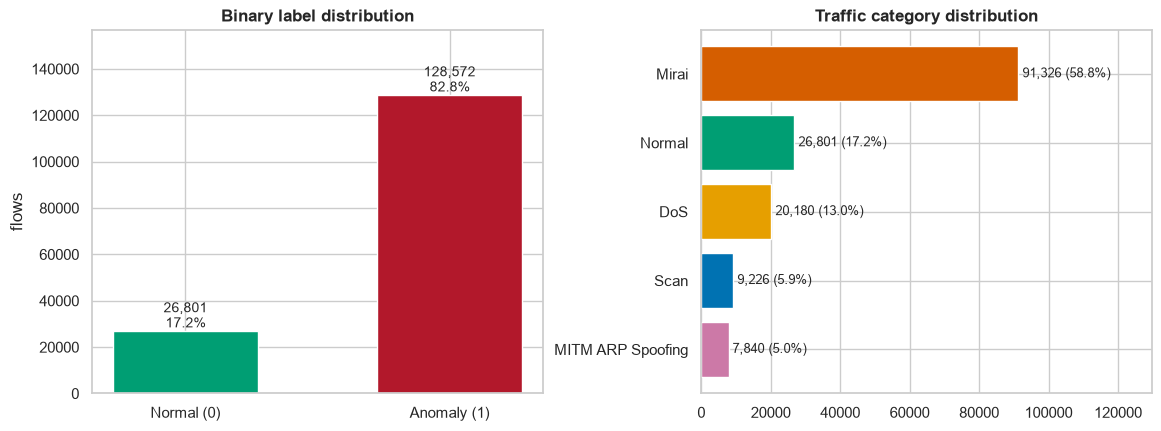

[figure saved] figures\fig01_class_distribution.png


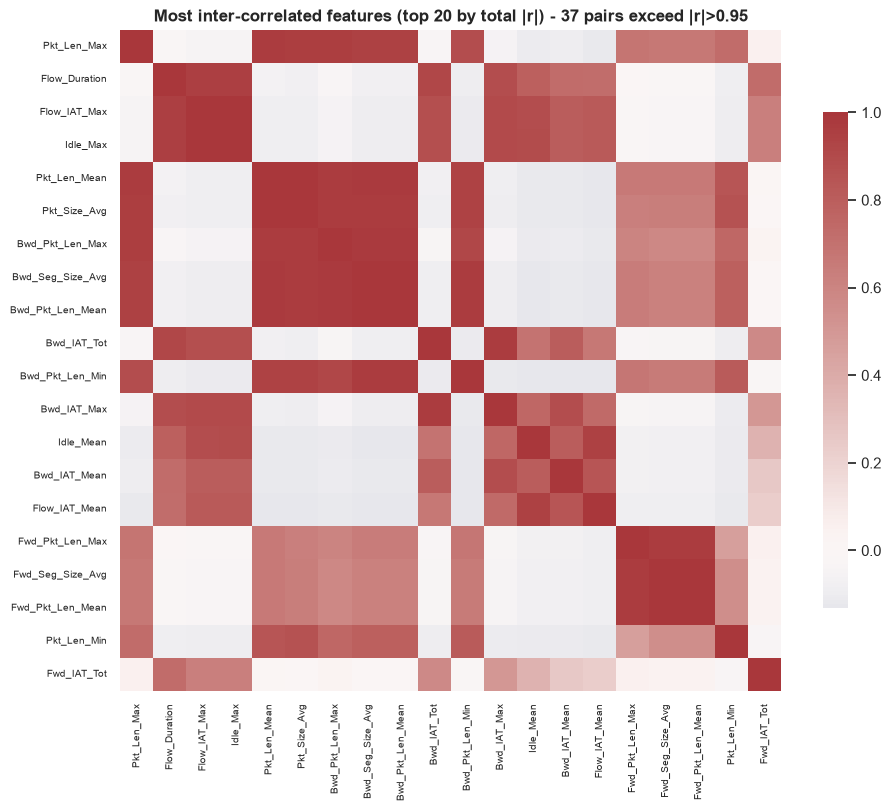

[figure saved] figures\fig02_feature_correlation.png
highly correlated feature pairs (|r|>0.95): 37
   Tot_Fwd_Pkts  ~  Subflow_Fwd_Pkts   r=+1.000
   Tot_Bwd_Pkts  ~  Subflow_Bwd_Pkts   r=+1.000
   TotLen_Fwd_Pkts  ~  Subflow_Fwd_Byts   r=+1.000
   TotLen_Bwd_Pkts  ~  Subflow_Bwd_Byts   r=+1.000
   Fwd_Pkt_Len_Mean  ~  Fwd_Seg_Size_Avg   r=+1.000
   Bwd_Pkt_Len_Mean  ~  Bwd_Seg_Size_Avg   r=+1.000
   Bwd_PSH_Flags  ~  PSH_Flag_Cnt   r=+1.000
   Bwd_URG_Flags  ~  URG_Flag_Cnt   r=+1.000
   Flow_IAT_Max  ~  Idle_Max   r=+1.000
   Flow_Pkts/s  ~  Fwd_Pkts/s   r=+0.997

rows_raw                                                                  625783
rows_after_dedup                                                          155373
duplicates_removed                                                        470410
features_final                                                                77
nan_cells_before_imputation                                               862211
inf_values_repaired  

In [5]:
# =====================================================================
# SECTION 2B - DATA AUDIT: distributions, redundancy, quality report
# =====================================================================
banner("SECTION 2B - DATA AUDIT")

# ---- fig01: class distributions ----
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
bc = data["y_bin"].value_counts().reindex([0, 1])
bars = axes[0].bar(["Normal (0)", "Anomaly (1)"], bc.values,
                   color=[CAT_COLORS["Normal"], "#B2182B"], width=0.55)
for rect, v in zip(bars, bc.values):
    axes[0].annotate(f"{v:,}\n{v/len(data)*100:.1f}%", (rect.get_x() + rect.get_width()/2, v),
                     ha="center", va="bottom", fontsize=10)
axes[0].set_ylim(0, bc.max()*1.22); axes[0].set_ylabel("flows")
axes[0].set_title("Binary label distribution")

cc = data["y_cat"].value_counts().sort_values()
axes[1].barh(cc.index, cc.values, color=[CAT_COLORS.get(c, "#9E9E9E") for c in cc.index])
for y, v in enumerate(cc.values):
    axes[1].annotate(f" {v:,} ({v/len(data)*100:.1f}%)", (v, y), va="center", fontsize=9)
axes[1].set_xlim(0, cc.max()*1.42)
axes[1].set_title("Traffic category distribution")
finish_fig(fig, "fig01_class_distribution")

# ---- feature redundancy: Pearson correlation on a subsample ----
_corr_n = min(100_000, len(data))
corr = data[FEATURE_COLS].sample(n=_corr_n, random_state=SEED).corr().fillna(0.0)
abs_corr = corr.abs().to_numpy(copy=True)  # copy=True -> writable array
# (pandas>=3 returns read-only views under copy-on-write; np.fill_diagonal needs a writable array)
np.fill_diagonal(abs_corr, 0.0)
redundant_pairs = sorted(
    ((FEATURE_COLS[i], FEATURE_COLS[j], float(corr.iloc[i, j]))
     for i, j in combinations(range(len(FEATURE_COLS)), 2) if abs_corr[i, j] > 0.95),
    key=lambda t: -abs(t[2]))
conn = pd.Series(abs_corr.sum(axis=0), index=FEATURE_COLS).sort_values(ascending=False)
top_feats = conn.head(20).index.tolist()

fig, ax = plt.subplots(figsize=(9.5, 8), constrained_layout=True)
sns.heatmap(corr.loc[top_feats, top_feats], cmap="vlag", center=0, square=True,
            cbar_kws={"shrink": 0.75}, ax=ax, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=7)
ax.set_title(f"Most inter-correlated features (top 20 by total |r|) - "
             f"{len(redundant_pairs)} pairs exceed |r|>0.95")
finish_fig(fig, "fig02_feature_correlation")

print(f"highly correlated feature pairs (|r|>0.95): {len(redundant_pairs)}")
for a, b, r in redundant_pairs[:10]:
    print(f"   {a}  ~  {b}   r={r:+.3f}")

# ---- machine-readable quality report ----
const_cols = [c for c in FEATURE_COLS if data[c].nunique(dropna=False) <= 1]
quality = pd.Series({
    "rows_raw": n_rows_raw,
    "rows_after_dedup": len(data),
    "duplicates_removed": n_dup,
    "features_final": len(FEATURE_COLS),
    "nan_cells_before_imputation": na_cells,
    "inf_values_repaired": n_inf,
    "minus1_sentinels_repaired": n_sentinel,
    "constant_features": ", ".join(const_cols) if const_cols else "none",
    "redundant_pairs_gt_095": len(redundant_pairs),
    "top_missing_columns": "; ".join(f"{k}={v:.2f}%" for k, v in missing_pct.head(8).items()),
}, name="value")
quality.to_csv(RESULTS_DIR / "data_quality_report.csv")
print("\n" + quality.to_string())

**Audit reading.** Two things usually stand out on IoTID20: (1) the *anomaly class is the majority* (~94% of flows — the mirror image of classic IDS benchmarks, which is exactly why plain accuracy will flatter any model in Section 4), and (2) flow-feature exporters produce strongly correlated feature families (several packets/IAT/flag features carry almost the same signal), which the feature-budget experiment in Section 9 exploits.

## 3 · Leakage-safe split, imputation & scaling

- **Split**: stratified 75% / 25% train–test (same protocol as the original study for comparability), then 15% of the remaining data is carved out as a **validation set** for early stopping.
- **Imputation & scaling are fitted on the training fold only** — medians and scaler statistics never see validation/test data (a detail that is easy to get wrong and that reviewers check).
- Features that are constant *within the training fold* carry no information and are removed from all splits.

In [6]:
# =====================================================================
# SECTION 3 - LEAKAGE-SAFE SPLIT, IMPUTATION & SCALING
# =====================================================================
banner("SECTION 3 - SPLIT & SCALE")
X_all = data[FEATURE_COLS].astype(np.float32)
y_all = data["y_bin"]
cat_all = data["y_cat"].astype(str)
na_imputed = int(X_all.isna().sum().sum())

_all_idx = np.arange(len(data))
idx_trainval, idx_test = train_test_split(_all_idx, test_size=TEST_FRAC, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_FRAC, random_state=SEED, stratify=y_all.iloc[idx_trainval])

def _take(idx):
    return X_all.iloc[idx].copy(), y_all.iloc[idx], cat_all.iloc[idx]

X_train, y_train, cat_train = _take(idx_train)
X_val,   y_val,   cat_val   = _take(idx_val)
X_test,  y_test,  cat_test  = _take(idx_test)
y_train_np, y_val_np, y_test_np = y_train.to_numpy(), y_val.to_numpy(), y_test.to_numpy()
cat_train_np, cat_val_np, cat_test_np = cat_train.to_numpy(), cat_val.to_numpy(), cat_test.to_numpy()

# ---- impute with TRAIN medians only ----
train_medians = X_train.median()
allnan_cols = train_medians.index[train_medians.isna()].tolist()
if allnan_cols:
    # a feature that is 100% missing in the training fold (IoTID20 real data:
    # 'Init_Fwd_Win_Byts' is 100% -1 sentinel) has no median -> drop it
    X_train.drop(columns=allnan_cols, inplace=True)
    X_val.drop(columns=allnan_cols, inplace=True)
    X_test.drop(columns=allnan_cols, inplace=True)
    print(f"dropped {len(allnan_cols)} all-missing feature(s) (train median undefined): {allnan_cols}")
for _x in (X_train, X_val, X_test):
    _x.fillna(train_medians, inplace=True)

# ---- drop features that are constant inside the training fold ----
var0 = [c for c in X_train.columns if X_train[c].std(ddof=0) == 0]
if var0:
    X_train.drop(columns=var0, inplace=True)
    X_val.drop(columns=var0, inplace=True)
    X_test.drop(columns=var0, inplace=True)
    print(f"dropped {len(var0)} zero-variance features: {var0}")
FEATURE_COLS_KEEP = list(X_train.columns)

# ---- scale with TRAIN statistics only ----
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype(np.float32)
X_val_s   = scaler.transform(X_val).astype(np.float32)
X_test_s  = scaler.transform(X_test).astype(np.float32)
if not np.isfinite(X_train_s).all():
    raise RuntimeError("non-finite values survived imputation + scaling - inspect the data-quality audit")

# ---- PCA (train subsample) reserved for later visual context ----
_pn = min(PCA_FIT_SAMPLE, X_train_s.shape[0])
pca = PCA(n_components=2, random_state=SEED).fit(X_train_s[:_pn])
X_test_pca = pca.transform(X_test_s)

split_table = pd.DataFrame(
    {"train": np.bincount(y_train_np, minlength=2),
     "val":   np.bincount(y_val_np,   minlength=2),
     "test":  np.bincount(y_test_np,  minlength=2)},
    index=["Normal", "Anomaly"])
print(f"imputed {na_imputed:,} NaN cells with train medians")
print(f"splits -> train {X_train_s.shape[0]:,} | val {X_val_s.shape[0]:,} | test {X_test_s.shape[0]:,} | features {X_train_s.shape[1]}")
print(f"PCA(2) explained variance: {pca.explained_variance_ratio_.sum():.1%}")
print(split_table.to_string())


  SECTION 3 - SPLIT & SCALE


C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\3919395387.py:29: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train.drop(columns=allnan_cols, inplace=True)
C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\3919395387.py:30: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_val.drop(columns=allnan_cols, inplace=True)
C:\Users\<you>\AppData\Local\Temp\ipykernel_14836\3919395387.py:31: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_test.drop(columns=allnan_cols, inplace=True)
C

dropped 1 all-missing feature(s) (train median undefined): ['Init_Fwd_Win_Byts']
dropped 9 zero-variance features: ['Fwd_PSH_Flags', 'Fwd_URG_Flags', 'Fwd_Byts/b_Avg', 'Fwd_Pkts/b_Avg', 'Fwd_Blk_Rate_Avg', 'Bwd_Byts/b_Avg', 'Bwd_Pkts/b_Avg', 'Bwd_Blk_Rate_Avg', 'Fwd_Seg_Size_Min']
imputed 214,181 NaN cells with train medians
splits -> train 99,049 | val 17,480 | test 38,844 | features 67
PCA(2) explained variance: 35.8%
         train    val   test
Normal   17086   3015   6700
Anomaly  81963  14465  32144


## 4 · Why plain accuracy is misleading here

IoTID20 is **attack-majority**: anomalies dominate the flows. A detector that shouts "attack!" for *every* flow therefore achieves very high accuracy while being useless.

The dummy classifiers below make the point quantitatively, and motivate the metric set used throughout:
- **Balanced Accuracy** — mean of per-class recalls,
- **MCC** (Matthews Correlation Coefficient) — the single most robust score for skewed binary problems,
- **PR-AUC** — precision-recall area under curve,
- **Brier score** — calibration quality of the probabilities.


  SECTION 4 - TRIVIAL BASELINES
                Model  Accuracy  BalancedAcc     MCC  F1_macro
Dummy (most_frequent)    0.8275       0.5000  0.0000    0.4528
   Dummy (stratified)    0.7155       0.4997 -0.0006    0.4997


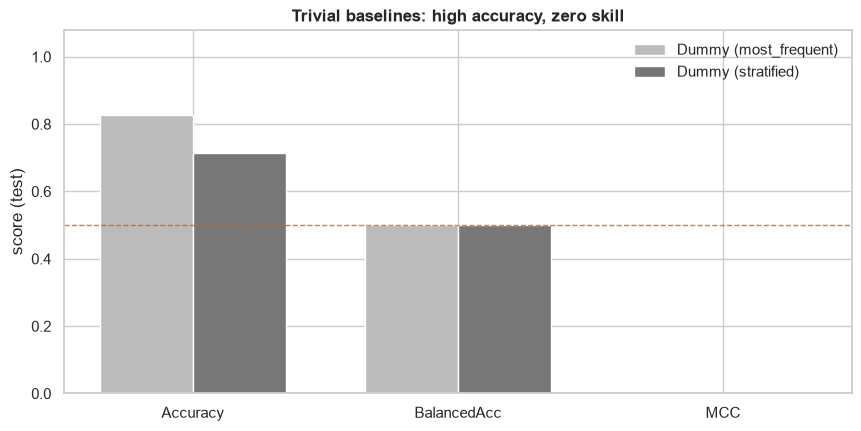

[figure saved] figures\fig03_dummy_baselines.png


In [7]:
# =====================================================================
# SECTION 4 - WHY ACCURACY MISLEADS: TRIVIAL BASELINES
# =====================================================================
banner("SECTION 4 - TRIVIAL BASELINES")
baseline_rows = []
for strategy in ["most_frequent", "stratified"]:
    dm = DummyClassifier(strategy=strategy, random_state=SEED).fit(X_train_s, y_train_np)
    p = dm.predict(X_test_s)
    baseline_rows.append({
        "Model": f"Dummy ({strategy})",
        "Accuracy": accuracy_score(y_test_np, p),
        "BalancedAcc": balanced_accuracy_score(y_test_np, p),
        "MCC": matthews_corrcoef(y_test_np, p),
        "F1_macro": f1_score(y_test_np, p, average="macro", zero_division=0),
    })
baselines_df = pd.DataFrame(baseline_rows)
baselines_df.to_csv(RESULTS_DIR / "dummy_baselines.csv", index=False)
print(baselines_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
_m4 = ["Accuracy", "BalancedAcc", "MCC"]
_x4 = np.arange(len(_m4)); _w4 = 0.35
for i, r in enumerate(baseline_rows):
    ax.bar(_x4 + (i - 0.5) * _w4, [r[m] for m in _m4], _w4,
           label=r["Model"], color=["#BBBBBB", "#777777"][i])
ax.set_xticks(_x4); ax.set_xticklabels(_m4)
ax.set_ylim(0, 1.08); ax.set_ylabel("score (test)")
ax.axhline(0.5, color="#D55E00", ls="--", lw=1, alpha=0.8)
ax.set_title("Trivial baselines: high accuracy, zero skill")
ax.legend()
finish_fig(fig, "fig03_dummy_baselines")

## 5 · Models

Three deliberately **lightweight** detectors — the trio an IoT gateway could realistically host:

| Model | Role | Imbalance handling |
|-------|------|--------------------|
| Logistic Regression | interpretable linear floor | `class_weight='balanced'` |
| XGBoost (hist) | strong tabular workhorse | `scale_pos_weight` |
| Small MLP (PyTorch) | deep-learning reference | `pos_weight` in the loss |

Two efficiency/practice fixes vs. the original study: **early stopping** on the validation set replaces the wasteful 3-fold CV that re-trained XGBoost three times on the full training data, and the MLP stops when validation loss stops improving instead of running a fixed epoch budget.

⚠ *Direction note*: in IoTID20 the **positive class (anomaly) is the majority**, so `scale_pos_weight = n_normal / n_anomaly < 1` — it *down-weights* the majority to rebalance the loss. Getting this direction right matters and is easy to flip by mistake.

In [8]:
# =====================================================================
# SECTION 5A - MODEL 1: LOGISTIC REGRESSION (interpretable baseline)
# =====================================================================
banner("SECTION 5A - LOGISTIC REGRESSION")

def evaluate_binary(name, y_true, proba, train_time=None):
    """Compute the full imbalance-aware metric set and register the model."""
    proba = np.asarray(proba, dtype=np.float64)
    pred = (proba >= 0.5).astype(int)
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "BalancedAcc": balanced_accuracy_score(y_true, pred),
        "Precision_anomaly": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "Recall_anomaly": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "F1_anomaly": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "F1_macro": f1_score(y_true, pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_true, pred),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "Brier": brier_score_loss(y_true, proba),
        "train_sec": train_time,
    }
    RESULTS_ROWS.append(row); PROBS[name] = proba; PREDS[name] = pred
    print(f"[{name}] acc={row['Accuracy']:.4f} | balAcc={row['BalancedAcc']:.4f} | MCC={row['MCC']:.4f} "
          f"| F1(macro)={row['F1_macro']:.4f} | ROC-AUC={row['ROC_AUC']:.4f} | PR-AUC={row['PR_AUC']:.4f}")
    return row

lr = LogisticRegression(C=1.0, penalty="l2", solver="lbfgs", class_weight="balanced",
                        max_iter=400, random_state=SEED)
t0 = time.time()
lr.fit(X_train_s, y_train_np)
lr_train_time = time.time() - t0
print(f"train time: {lr_train_time:.1f}s | lbfgs iterations: {np.ravel(lr.n_iter_)}")
evaluate_binary("Logistic Regression", y_test_np, lr.predict_proba(X_test_s)[:, 1], lr_train_time)
joblib.dump(lr, MODELS_DIR / "logistic_regression.joblib")


  SECTION 5A - LOGISTIC REGRESSION
train time: 2.0s | lbfgs iterations: [220]
[Logistic Regression] acc=0.9398 | balAcc=0.9391 | MCC=0.8127 | F1(macro)=0.9029 | ROC-AUC=0.9830 | PR-AUC=0.9959


['models\\logistic_regression.joblib']

In [9]:
# =====================================================================
# SECTION 5B - MODEL 2: XGBOOST (gradient-boosted trees, early stopping)
# =====================================================================
banner("SECTION 5B - XGBOOST")
from xgboost import XGBClassifier

neg, pos = np.bincount(y_train_np)
spw = neg / pos
print(f"train class counts -> normal(0): {neg:,} | anomaly(1): {pos:,} | scale_pos_weight={spw:.3f}")

xgb_model = XGBClassifier(
    n_estimators=60 if FAST_MODE else 300,
    learning_rate=0.1, max_depth=6, subsample=0.9, colsample_bytree=0.8,
    objective="binary:logistic", eval_metric="logloss", tree_method="hist",
    scale_pos_weight=spw, early_stopping_rounds=25,
    random_state=SEED, n_jobs=-1,
)
t0 = time.time()
xgb_model.fit(X_train_s, y_train_np, eval_set=[(X_val_s, y_val_np)], verbose=False)
xgb_train_time = time.time() - t0
print(f"train time: {xgb_train_time:.1f}s | best iteration: {xgb_model.best_iteration}")
evaluate_binary("XGBoost", y_test_np, xgb_model.predict_proba(X_test_s)[:, 1], xgb_train_time)
joblib.dump(xgb_model, MODELS_DIR / "xgboost.joblib")


  SECTION 5B - XGBOOST
train class counts -> normal(0): 17,086 | anomaly(1): 81,963 | scale_pos_weight=0.208
train time: 4.2s | best iteration: 299
[XGBoost] acc=0.9812 | balAcc=0.9762 | MCC=0.9356 | F1(macro)=0.9676 | ROC-AUC=0.9974 | PR-AUC=0.9994


['models\\xgboost.joblib']


  SECTION 5C - MLP (PyTorch)
torch device: cpu
epoch 01/15 | train 0.0989 | val 0.0549
epoch 02/15 | train 0.0557 | val 0.0511
epoch 03/15 | train 0.0503 | val 0.0494
epoch 04/15 | train 0.0473 | val 0.0467
epoch 05/15 | train 0.0444 | val 0.0455
epoch 06/15 | train 0.0427 | val 0.0450
epoch 07/15 | train 0.0409 | val 0.0434
epoch 08/15 | train 0.0397 | val 0.0422
epoch 09/15 | train 0.0379 | val 0.0420
epoch 10/15 | train 0.0372 | val 0.0433
epoch 11/15 | train 0.0364 | val 0.0417
epoch 12/15 | train 0.0363 | val 0.0417
epoch 13/15 | train 0.0351 | val 0.0413
epoch 14/15 | train 0.0348 | val 0.0424
epoch 15/15 | train 0.0345 | val 0.0420
train time: 19.2s | parameters: 17,025
[Neural Network] acc=0.9669 | balAcc=0.9609 | MCC=0.8896 | F1(macro)=0.9441 | ROC-AUC=0.9937 | PR-AUC=0.9986


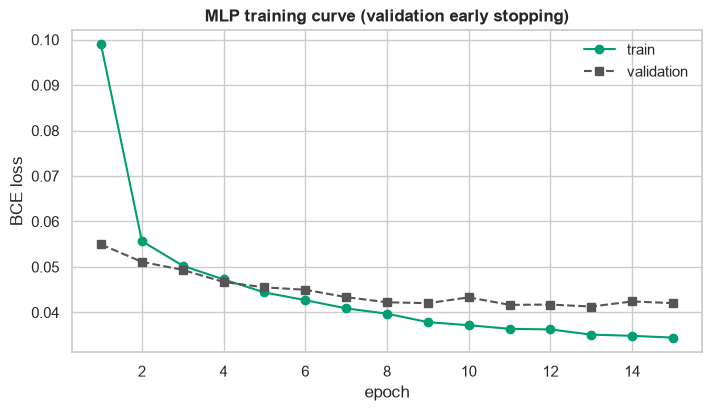

[figure saved] figures\fig04_mlp_training_curve.png


In [10]:
# =====================================================================
# SECTION 5C - MODEL 3: SMALL MLP (PyTorch, validation early stopping)
# =====================================================================
banner("SECTION 5C - MLP (PyTorch)")
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch device: {device}")

X_tr_t = torch.from_numpy(X_train_s)
y_tr_t = torch.from_numpy(y_train_np.astype(np.float32)).unsqueeze(1)
X_va_t = torch.from_numpy(X_val_s)
y_va_t = torch.from_numpy(y_val_np.astype(np.float32)).unsqueeze(1)
X_te_t = torch.from_numpy(X_test_s)

class SmallNet(nn.Module):
    """~18K-parameter MLP - small enough for an IoT gateway CPU."""
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64),     nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, 1),
        )
    def forward(self, x):
        return self.net(x)

mlp = SmallNet(X_tr_t.shape[1]).to(device)
pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-5)

loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=512, shuffle=True)
epochs_max = 5 if FAST_MODE else 15
patience = 2 if FAST_MODE else 3

history, best_val, best_state, wait = [], np.inf, None, 0
t0 = time.time()
for epoch in range(1, epochs_max + 1):
    mlp.train(); ep_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(mlp(xb), yb)
        loss.backward(); optimizer.step()
        ep_loss += loss.item() * xb.size(0)
    ep_loss /= len(loader.dataset)

    mlp.eval()
    with torch.no_grad():
        val_loss = criterion(mlp(X_va_t.to(device)), y_va_t.to(device)).item()
    history.append((epoch, ep_loss, val_loss))
    print(f"epoch {epoch:02d}/{epochs_max} | train {ep_loss:.4f} | val {val_loss:.4f}")
    if val_loss < best_val - 1e-4:
        best_val, wait = val_loss, 0
        best_state = {k: v.detach().cpu().clone() for k, v in mlp.state_dict().items()}
    else:
        wait += 1
        if wait >= patience:
            print(f"early stopping at epoch {epoch} (best val loss {best_val:.4f})")
            break
mlp_train_time = time.time() - t0
if best_state is not None:
    mlp.load_state_dict(best_state)
mlp.eval()
torch.save(mlp.state_dict(), MODELS_DIR / "mlp_state_dict.pt")
print(f"train time: {mlp_train_time:.1f}s | parameters: {sum(p.numel() for p in mlp.parameters()):,}")

with torch.no_grad():
    probs_nn = torch.sigmoid(mlp(X_te_t.to(device))).cpu().numpy().ravel()
evaluate_binary("Neural Network", y_test_np, probs_nn, mlp_train_time)

hist_df = pd.DataFrame(history, columns=["epoch", "train_loss", "val_loss"])
hist_df.to_csv(RESULTS_DIR / "mlp_training_history.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(hist_df.epoch, hist_df.train_loss, "o-", color=MODEL_COLORS["Neural Network"], label="train")
ax.plot(hist_df.epoch, hist_df.val_loss, "s--", color="#555555", label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss")
ax.set_title("MLP training curve (validation early stopping)")
ax.legend()
finish_fig(fig, "fig04_mlp_training_curve")

In [11]:
# =====================================================================
# SECTION 5D - FIRST METRICS SUMMARY
# =====================================================================
model_names = ["Logistic Regression", "XGBoost", "Neural Network"]
metrics_df = pd.DataFrame(RESULTS_ROWS)
metrics_df.to_csv(RESULTS_DIR / "binary_metrics_test.csv", index=False)
print(metrics_df.set_index("Model").round(4).to_string())

                     Accuracy  BalancedAcc  Precision_anomaly  Recall_anomaly  F1_anomaly  F1_macro     MCC  ROC_AUC  PR_AUC   Brier  train_sec
Model                                                                                                                                          
Logistic Regression    0.9398       0.9391             0.9865          0.9401      0.9627    0.9029  0.8127   0.9830  0.9959  0.0461     1.9746
XGBoost                0.9812       0.9762             0.9934          0.9838      0.9886    0.9676  0.9356   0.9974  0.9994  0.0139     4.2154
Neural Network         0.9669       0.9609             0.9897          0.9700      0.9798    0.9441  0.8896   0.9937  0.9986  0.0225    19.1535


## 6 · Core evaluation

Three complementary views of the same three models:
- **Confusion matrices** — raw error structure.
- **ROC** (class-ordering skill) + **PR curves from two directions**: anomaly coverage, and — the view that matters for SOC noise — the **minority *Normal* class**, where the baseline is the *normal-class prevalence* and precision translates directly into *alert trustworthiness*.
- **Calibration** — do the reported probabilities mean what they claim? An IDS threshold is only as good as its calibration.


  SECTION 6A - CONFUSION MATRICES


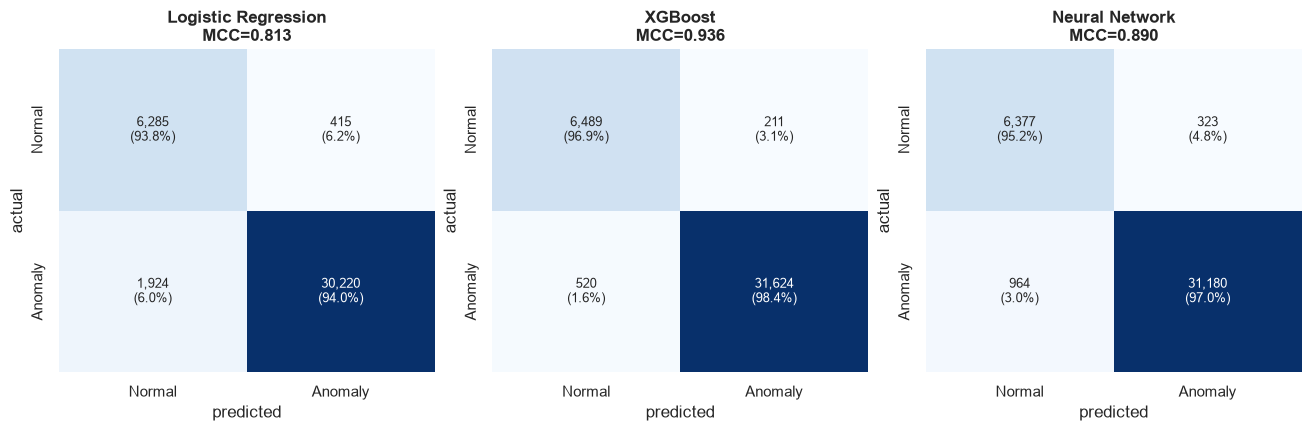

[figure saved] figures\fig05_confusion_matrices.png


In [12]:
# =====================================================================
# SECTION 6A - CONFUSION MATRICES
# =====================================================================
banner("SECTION 6A - CONFUSION MATRICES")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y_test_np, PREDS[name])
    with np.errstate(divide="ignore", invalid="ignore"):
        pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{v:,.0f}\n({p:.1f}%)" for v, p in zip(rv, rp)] for rv, rp in zip(cm, pct)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"],
                annot_kws={"fontsize": 9})
    ax.set_title(f"{name}\nMCC={matthews_corrcoef(y_test_np, PREDS[name]):.3f}")
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
finish_fig(fig, "fig05_confusion_matrices")


  SECTION 6B - ROC & PR CURVES


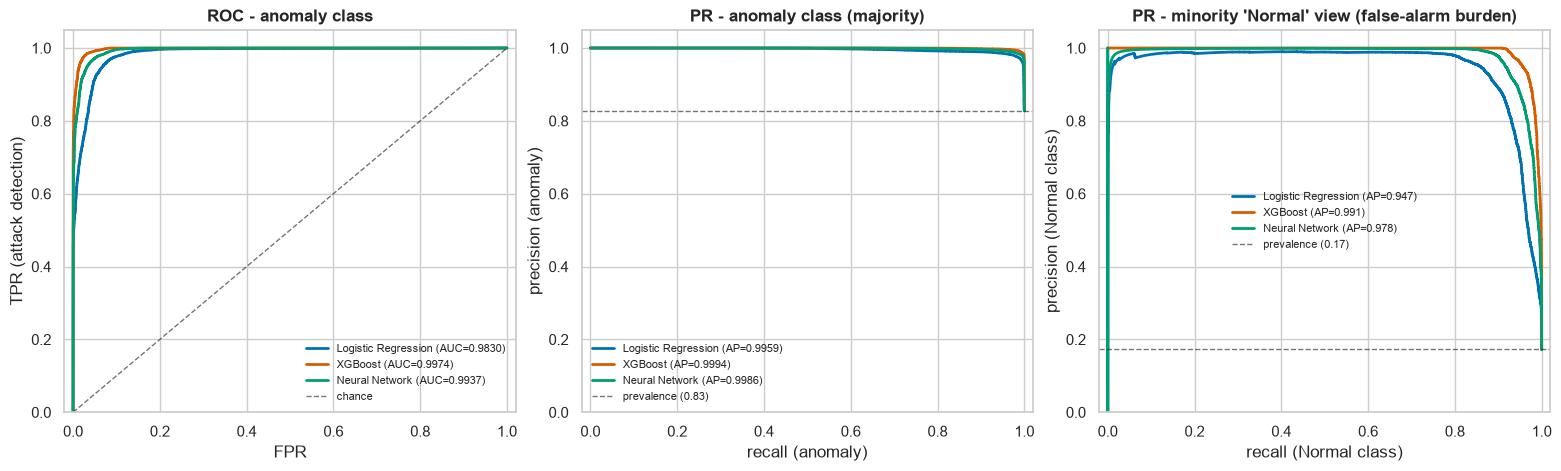

[figure saved] figures\fig06_roc_pr_curves.png


In [13]:
# =====================================================================
# SECTION 6B - ROC + DUAL-VIEW PRECISION-RECALL CURVES
# =====================================================================
banner("SECTION 6B - ROC & PR CURVES")
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), constrained_layout=True)

for name in model_names:
    c = MODEL_COLORS[name]
    fpr, tpr, _ = roc_curve(y_test_np, PROBS[name])
    axes[0].plot(fpr, tpr, color=c, lw=2,
                 label=f"{name} (AUC={roc_auc_score(y_test_np, PROBS[name]):.4f})")
    prec, rec, _ = precision_recall_curve(y_test_np, PROBS[name])
    ap = average_precision_score(y_test_np, PROBS[name])
    axes[1].plot(rec, prec, color=c, lw=2, label=f"{name} (AP={ap:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="chance")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR (attack detection)")
axes[0].set_title("ROC - anomaly class"); axes[0].legend(fontsize=8)
axes[0].set_xlim(-0.02, 1.02); axes[0].set_ylim(0, 1.05)

prev = y_test_np.mean()
axes[1].axhline(prev, color="k", ls="--", lw=1, alpha=0.6, label=f"prevalence ({prev:.2f})")
axes[1].set_xlabel("recall (anomaly)"); axes[1].set_ylabel("precision (anomaly)")
axes[1].set_title("PR - anomaly class (majority)")
axes[1].legend(fontsize=8); axes[1].set_xlim(-0.02, 1.02); axes[1].set_ylim(0, 1.05)

# minority 'Normal' view: precision here = trustworthiness of an "all-clear" decision
y0 = (y_test_np == 0).astype(int)
for name in model_names:
    prec0, rec0, _ = precision_recall_curve(y0, 1.0 - PROBS[name])
    ap0 = average_precision_score(y0, 1.0 - PROBS[name])
    axes[2].plot(rec0, prec0, color=MODEL_COLORS[name], lw=2,
                 label=f"{name} (AP={ap0:.3f})")
axes[2].axhline(y0.mean(), color="k", ls="--", lw=1, alpha=0.6, label=f"prevalence ({y0.mean():.2f})")
axes[2].set_xlabel("recall (Normal class)"); axes[2].set_ylabel("precision (Normal class)")
axes[2].set_title("PR - minority 'Normal' view (false-alarm burden)")
axes[2].legend(fontsize=8); axes[2].set_xlim(-0.02, 1.02); axes[2].set_ylim(0, 1.05)
finish_fig(fig, "fig06_roc_pr_curves")


  SECTION 6C - CALIBRATION


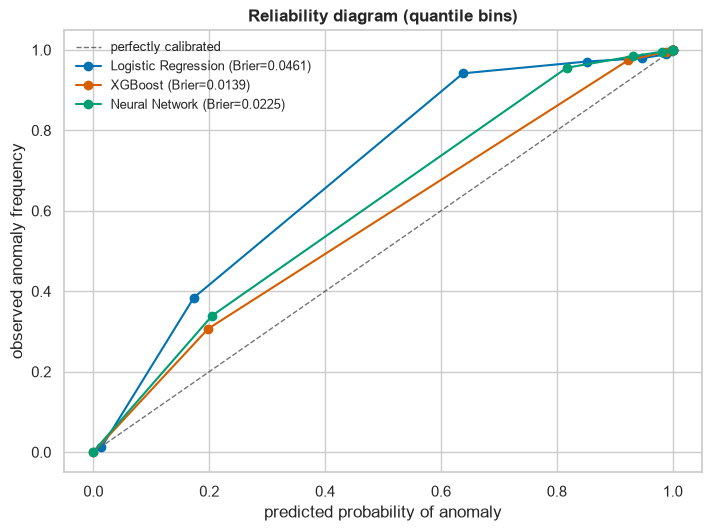

[figure saved] figures\fig07_calibration_curves.png


In [14]:
# =====================================================================
# SECTION 6C - PROBABILITY CALIBRATION (reliability diagrams)
# =====================================================================
banner("SECTION 6C - CALIBRATION")
fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="perfectly calibrated")
for name in model_names:
    pt, pp = calibration_curve(y_test_np, PROBS[name], n_bins=10, strategy="quantile")
    b = brier_score_loss(y_test_np, PROBS[name])
    ax.plot(pp, pt, "o-", color=MODEL_COLORS[name], label=f"{name} (Brier={b:.4f})")
ax.set_xlabel("predicted probability of anomaly")
ax.set_ylabel("observed anomaly frequency")
ax.set_title("Reliability diagram (quantile bins)")
ax.legend(fontsize=9)
finish_fig(fig, "fig07_calibration_curves")

## 7 · Efficiency benchmark & the accuracy–efficiency Pareto

Detection quality alone does not decide deployability on an IoT gateway. We measure what actually constrains a live deployment:

| Metric | Meaning |
|--------|---------|
| `latency_us_b1` | time to score **one flow** (µs) — the real-time budget |
| `throughput_kpps` | thousands of flows scored per second in batch |
| `model_size_KB` | on-disk footprint |
| `train_sec` | (re)training cost |

The Pareto plot condenses the trade-off: **x = latency, y = MCC, bubble area = model size**.


  SECTION 7 - EFFICIENCY BENCHMARK
[Logistic Regression] single-flow latency=   108.6 us | throughput=    10604k flows/s | size=       1 KB
[XGBoost] single-flow latency=   376.0 us | throughput=     1226k flows/s | size=     825 KB
[Neural Network] single-flow latency=   103.2 us | throughput=     4161k flows/s | size=      70 KB


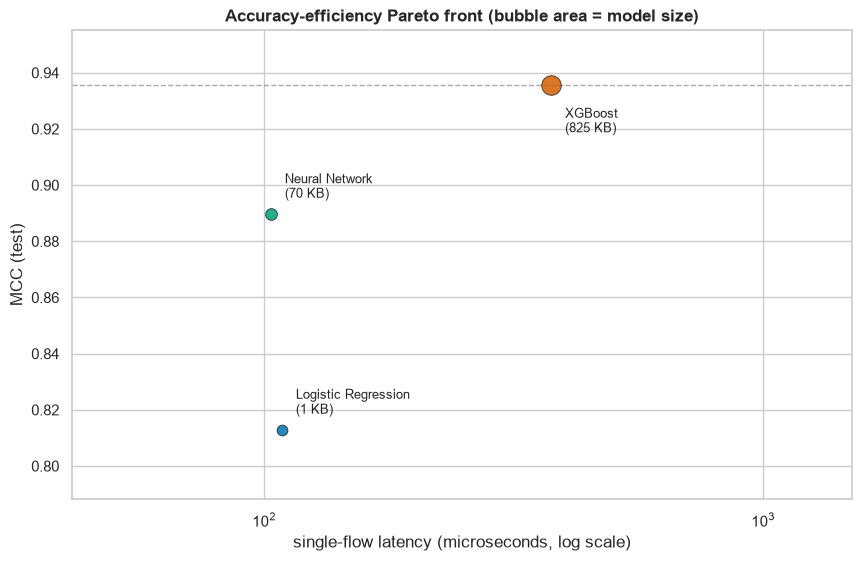

[figure saved] figures\fig08_efficiency_pareto.png


In [15]:
# =====================================================================
# SECTION 7 - EFFICIENCY BENCHMARK & ACCURACY-EFFICIENCY PARETO
# =====================================================================
banner("SECTION 7 - EFFICIENCY BENCHMARK")

def model_size_kb(obj, name, ext):
    tmp = MODELS_DIR / f"_tmp_size_{name}.{ext}"
    if ext == "pt":
        torch.save(obj.state_dict() if hasattr(obj, "state_dict") else obj, tmp)
    else:
        joblib.dump(obj, tmp)
    size = tmp.stat().st_size / 1024
    tmp.unlink()
    return size

def batch1_latency_us(predict_fn, X, n=None):
    n = n or LATENCY_N
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X), size=min(n, len(X)), replace=False)
    for i in idx[:5]:
        predict_fn(X[i:i+1])                       # warm-up
    t0 = time.perf_counter()
    for i in idx:
        predict_fn(X[i:i+1])
    return (time.perf_counter() - t0) / len(idx) * 1e6

def batch_throughput_kpps(predict_fn, X, n=None):
    n = n or BATCH_N
    Xb = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xb)
    return len(Xb) / (time.perf_counter() - t0) / 1e3

def _lr_predict(a): return lr.predict_proba(a)[:, 1]
def _xgb_predict(a): return xgb_model.predict_proba(a)[:, 1]
def _nn_predict(a):
    with torch.no_grad():
        return torch.sigmoid(mlp(torch.from_numpy(a).to(device))).cpu().numpy().ravel()

PREDICT_FNS = {"Logistic Regression": _lr_predict, "XGBoost": _xgb_predict, "Neural Network": _nn_predict}
MODEL_SIZES = {"Logistic Regression": (lr, "joblib"), "XGBoost": (xgb_model, "joblib"), "Neural Network": (mlp, "pt")}
TRAIN_TIMES = {"Logistic Regression": lr_train_time, "XGBoost": xgb_train_time, "Neural Network": mlp_train_time}

lat_rows = []
for name in model_names:
    obj, ext = MODEL_SIZES[name]
    eff = {
        "Model": name,
        "latency_us_b1": batch1_latency_us(PREDICT_FNS[name], X_test_s),
        "throughput_kpps": batch_throughput_kpps(PREDICT_FNS[name], X_test_s),
        "model_size_KB": model_size_kb(obj, name.replace(" ", "_"), ext),
        "train_sec": TRAIN_TIMES[name],
    }
    EFFICIENCY[name] = eff
    lat_rows.append(eff)
    print(f"[{name}] single-flow latency={eff['latency_us_b1']:8.1f} us | "
          f"throughput={eff['throughput_kpps']:9.0f}k flows/s | size={eff['model_size_KB']:8.0f} KB")

eff_df = pd.DataFrame(lat_rows)
eff_df.to_csv(RESULTS_DIR / "efficiency_benchmark.csv", index=False)

merged = metrics_df.merge(eff_df, on="Model")
merged.to_csv(RESULTS_DIR / "accuracy_vs_efficiency.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
top_mcc_model = merged.loc[merged.MCC.idxmax(), "Model"]
for _, r in merged.iterrows():
    ax.scatter(r.latency_us_b1, r.MCC, s=60 + r.model_size_KB / 6,
               color=MODEL_COLORS[r.Model], alpha=0.85, edgecolor="k", linewidth=0.6, zorder=3)
    off = (10, -34) if r.Model == top_mcc_model else (10, 12)   # keep labels inside the axes
    ax.annotate(f"{r.Model}\n({r.model_size_KB:,.0f} KB)", (r.latency_us_b1, r.MCC),
                textcoords="offset points", xytext=off, fontsize=9)
ymin, ymax = float(merged.MCC.min()), float(merged.MCC.max())
span = max(ymax - ymin, 1e-6)
ax.set_xscale("log")
ax.set_xlim(left=max(merged.latency_us_b1.min() * 0.4, 1e-1),
            right=merged.latency_us_b1.max() * 4)
ax.set_ylim(ymin - 0.20 * span, ymax + 0.16 * span)
ax.set_xlabel("single-flow latency (microseconds, log scale)")
ax.set_ylabel("MCC (test)")
ax.set_title("Accuracy-efficiency Pareto front (bubble area = model size)")
ax.axhline(ymax, ls="--", color="#888888", lw=1, alpha=0.7)
finish_fig(fig, "fig08_efficiency_pareto")

## 8 · Explainability: what drives detection?

SHAP values decompose each prediction into per-feature contributions. We extract:
1. a **beeswarm** (how feature values push towards anomaly/normal across flows),
2. a ranked **global importance** bar,
3. **per-attack-family profiles** of the top-6 features — showing *why* some families (typically Scan and Mirai fragments) overlap with normal traffic and get missed.


  SECTION 8A - SHAP


c:\Users\<you>\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP computed on 2,000 flows x 67 features


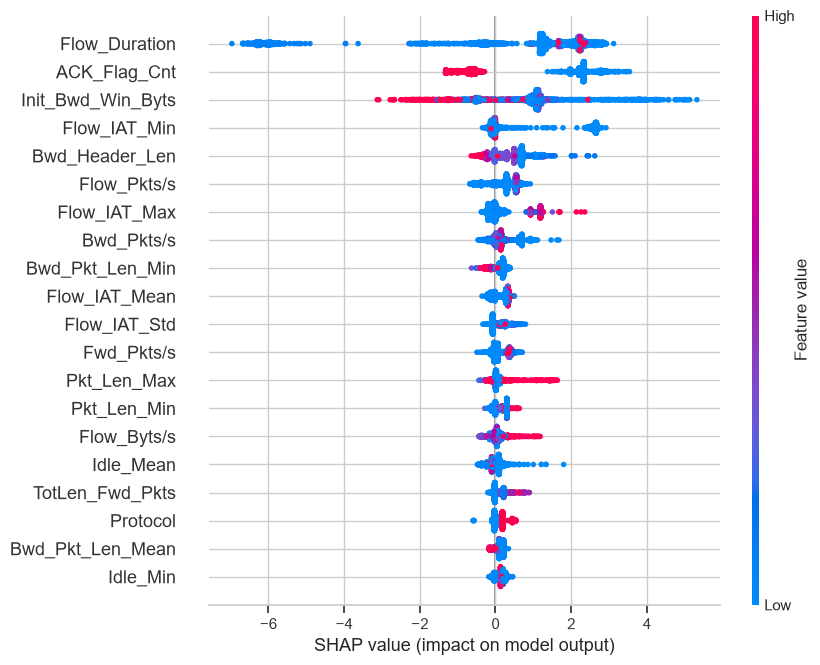

[figure saved] figures\fig09_shap_beeswarm.png


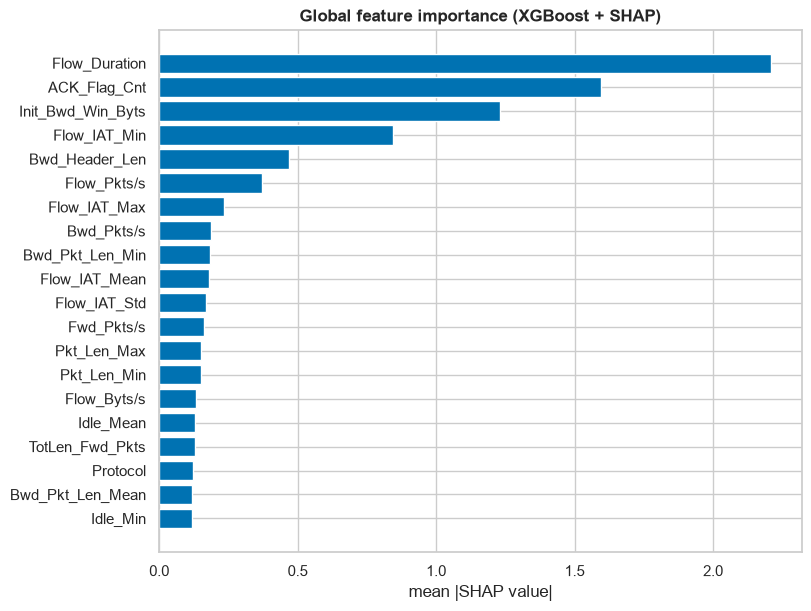

[figure saved] figures\fig10_shap_importance_bar.png


In [16]:
# =====================================================================
# SECTION 8A - SHAP EXPLAINABILITY (tree model)
# =====================================================================
banner("SECTION 8A - SHAP")
import shap

_rng8 = np.random.default_rng(SEED)
_shap_idx = _rng8.choice(X_test_s.shape[0], size=min(SHAP_SAMPLE, X_test_s.shape[0]), replace=False)
X_shap = X_test_s[_shap_idx]

explainer = shap.TreeExplainer(xgb_model)
try:
    sv = explainer.shap_values(X_shap)
except Exception:
    sv = explainer(X_shap).values
sv = np.asarray(sv)
if sv.ndim == 3:                      # some shap versions return (n, features, outputs)
    sv = sv[..., sv.shape[-1] - 1]
mean_abs = np.abs(sv).mean(axis=0)
rank = np.argsort(-mean_abs)
print(f"SHAP computed on {X_shap.shape[0]:,} flows x {X_shap.shape[1]} features")

plt.figure()
shap.summary_plot(sv, X_shap, feature_names=FEATURE_COLS_KEEP, max_display=20, show=False)
_fig8 = plt.gcf(); _fig8.set_size_inches(9, 6.5)
finish_fig(_fig8, "fig09_shap_beeswarm")

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
names_top = [FEATURE_COLS_KEEP[i] for i in rank[:20]][::-1]
ax.barh(names_top, mean_abs[rank[:20]][::-1], color="#0072B2")
ax.set_xlabel("mean |SHAP value|")
ax.set_title("Global feature importance (XGBoost + SHAP)")
finish_fig(fig, "fig10_shap_importance_bar")


  SECTION 8B - TOP-FEATURE PROFILES BY CATEGORY


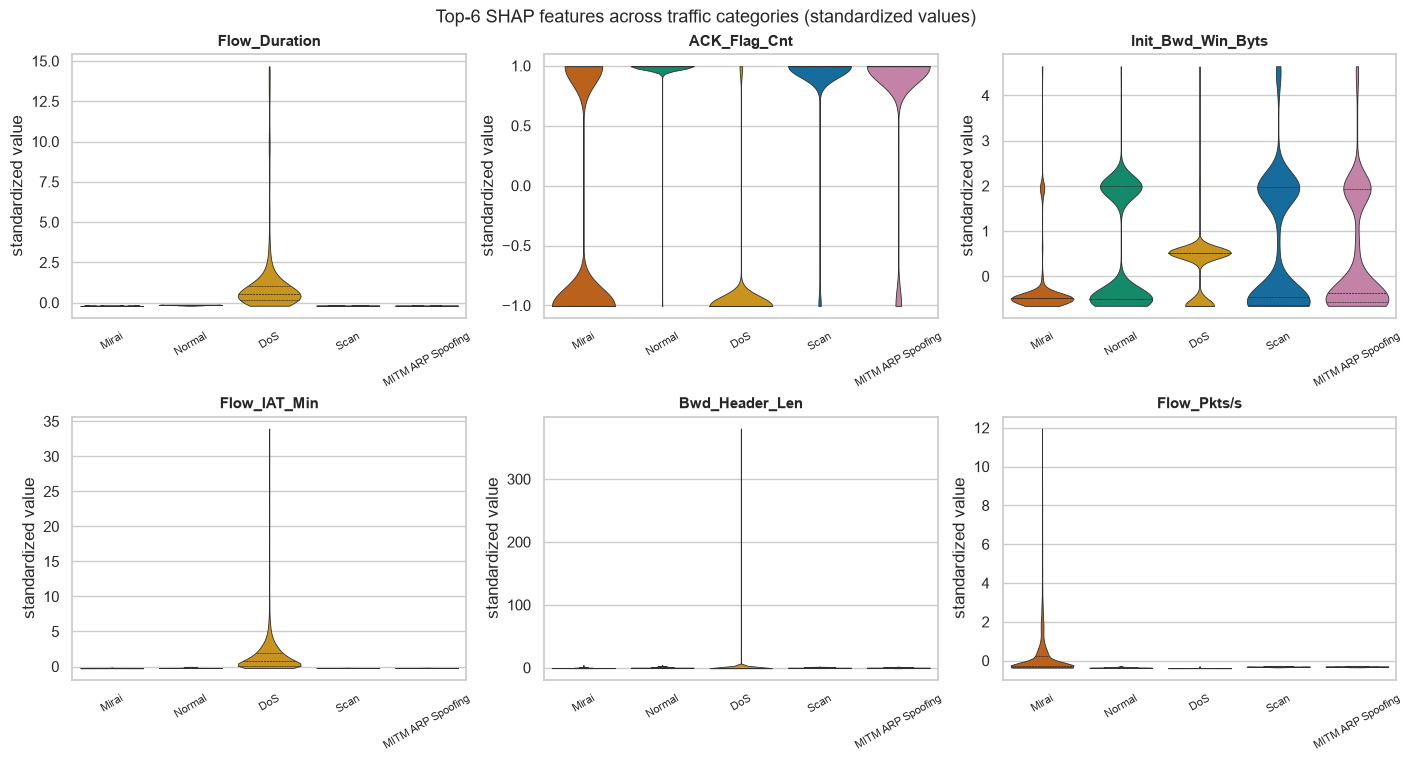

[figure saved] figures\fig11_shap_feature_distributions.png
top-10 features by mean |SHAP|:
  Flow_Duration                       2.2095
  ACK_Flag_Cnt                        1.5963
  Init_Bwd_Win_Byts                   1.2298
  Flow_IAT_Min                        0.8457
  Bwd_Header_Len                      0.4695
  Flow_Pkts/s                         0.3726
  Flow_IAT_Max                        0.2332
  Bwd_Pkts/s                          0.1868
  Bwd_Pkt_Len_Min                     0.1824
  Flow_IAT_Mean                       0.1813


In [17]:
# =====================================================================
# SECTION 8B - PER-ATTACK-FAMILY PROFILES OF THE TOP FEATURES
# =====================================================================
banner("SECTION 8B - TOP-FEATURE PROFILES BY CATEGORY")
top6 = [FEATURE_COLS_KEEP[i] for i in rank[:6]]
_vis_n = min(VIOLIN_SAMPLE, X_test_s.shape[0])
_vis_idx = np.random.default_rng(SEED).choice(X_test_s.shape[0], _vis_n, replace=False)
plot_df = pd.DataFrame(
    X_test_s[_vis_idx][:, [FEATURE_COLS_KEEP.index(f) for f in top6]],
    columns=top6)
plot_df["category"] = cat_test_np[_vis_idx]
order_cats = plot_df["category"].value_counts().index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), constrained_layout=True)
for ax, f in zip(axes.ravel(), top6):
    sns.violinplot(data=plot_df, x="category", y=f, hue="category", order=order_cats,
                   hue_order=order_cats, palette=CAT_COLORS, cut=0, inner="quartile",
                   linewidth=0.6, legend=False, ax=ax)
    ax.set_title(f, fontsize=11)
    ax.set_xlabel(""); ax.set_ylabel("standardized value")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.suptitle("Top-6 SHAP features across traffic categories (standardized values)", fontsize=13)
finish_fig(fig, "fig11_shap_feature_distributions")

print("top-10 features by mean |SHAP|:")
for i in rank[:10]:
    print(f"  {FEATURE_COLS_KEEP[i]:<35} {mean_abs[i]:.4f}")

## 9 · The feature-budget experiment: how many features do you need?

Flow-feature exporters emit ~80 features, but they are heavily inter-correlated (Section 2) and expensive to compute on a device. Here we rank features by mean |SHAP| and re-train XGBoost on progressively smaller subsets.

**Paper-ready question**: *what fraction of the feature set keeps detection quality within 1% MCC of the full model?* The answer defines a practical feature budget for lightweight IDS sensors.


  SECTION 9 - FEATURE REDUCTION
k= 5 | MCC=0.9270 | F1(macro)=0.9633 | latency=  346.6 us
k=10 | MCC=0.9292 | F1(macro)=0.9644 | latency=  303.0 us
k=15 | MCC=0.9336 | F1(macro)=0.9666 | latency=  299.1 us
k=20 | MCC=0.9336 | F1(macro)=0.9666 | latency=  433.5 us
k=30 | MCC=0.9341 | F1(macro)=0.9669 | latency=  346.7 us
k=45 | MCC=0.9360 | F1(macro)=0.9678 | latency=  333.3 us
k=67 | MCC=0.9375 | F1(macro)=0.9686 | latency=  313.1 us

knee: 10 of 67 features retain MCC within 0.01 of the full set (0.9375)


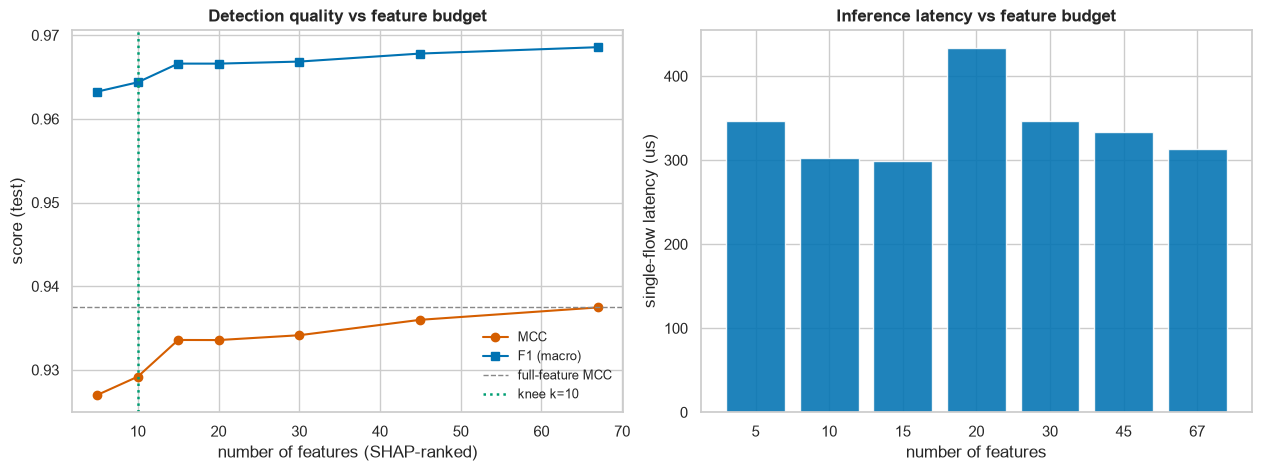

[figure saved] figures\fig12_feature_reduction.png


In [18]:
# =====================================================================
# SECTION 9 - FEATURE-REDUCTION EXPERIMENT
# =====================================================================
banner("SECTION 9 - FEATURE REDUCTION")

def _quick_xgb(n_est):
    return XGBClassifier(
        n_estimators=n_est, learning_rate=0.1, max_depth=6, subsample=0.9,
        colsample_bytree=0.8, objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", scale_pos_weight=spw, early_stopping_rounds=20,
        random_state=SEED, n_jobs=-1)

n_feat_total = X_train_s.shape[1]
ks = sorted(set([k for k in FEATURE_KS if k <= n_feat_total] + [n_feat_total]))
red_rows = []
for k in ks:
    sel = rank[:k]
    m = _quick_xgb(40 if FAST_MODE else 200)
    m.fit(X_train_s[:, sel], y_train_np, eval_set=[(X_val_s[:, sel], y_val_np)], verbose=False)
    p = m.predict_proba(X_test_s[:, sel])[:, 1]
    pred = (p >= 0.5).astype(int)
    lat = batch1_latency_us(lambda a, mm=m: mm.predict_proba(a)[:, 1],
                            X_test_s[:, sel], n=min(60, LATENCY_N))
    red_rows.append({
        "k_features": k,
        "MCC": matthews_corrcoef(y_test_np, pred),
        "F1_macro": f1_score(y_test_np, pred, average="macro", zero_division=0),
        "BalancedAcc": balanced_accuracy_score(y_test_np, pred),
        "latency_us_b1": lat,
    })
    print(f"k={k:>2} | MCC={red_rows[-1]['MCC']:.4f} | F1(macro)={red_rows[-1]['F1_macro']:.4f} "
          f"| latency={lat:7.1f} us")

red_df = pd.DataFrame(red_rows)
red_df.to_csv(RESULTS_DIR / "feature_reduction.csv", index=False)

full_mcc = float(red_df.loc[red_df.k_features == n_feat_total, "MCC"].iloc[0])
eligible = red_df[red_df.MCC >= full_mcc - 0.01]
knee_k = int(eligible.k_features.min())
print(f"\nknee: {knee_k} of {n_feat_total} features retain MCC within 0.01 of the full set ({full_mcc:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
axes[0].plot(red_df.k_features, red_df.MCC, "o-", color="#D55E00", label="MCC")
axes[0].plot(red_df.k_features, red_df.F1_macro, "s-", color="#0072B2", label="F1 (macro)")
axes[0].axhline(full_mcc, ls="--", color="#888888", lw=1, label="full-feature MCC")
axes[0].axvline(knee_k, ls=":", color="#009E73", lw=1.8, label=f"knee k={knee_k}")
axes[0].set_xlabel("number of features (SHAP-ranked)")
axes[0].set_ylabel("score (test)")
axes[0].set_title("Detection quality vs feature budget")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].bar([str(k) for k in red_df.k_features], red_df.latency_us_b1, color="#0072B2", alpha=0.88)
axes[1].set_xlabel("number of features")
axes[1].set_ylabel("single-flow latency (us)")
axes[1].set_title("Inference latency vs feature budget")
finish_fig(fig, "fig12_feature_reduction")

## 10 · Cost-sensitive operating points

In a SOC a **missed attack (FN) is not 1× as expensive as a false alarm (FP)** — it is typically an order of magnitude worse. We sweep the decision threshold and minimize the expected cost `C_FN·FN + C_FP·FP` with `C_FN=10, C_FP=1`, and additionally report the classic IDS operating point **"FPR ≤ 1%"**: the threshold that keeps false alarms on normal traffic below 1% while maximizing attack coverage.

This turns the classifier into a *tunable detector* instead of a fixed 0.5-threshold black box.


  SECTION 10 - OPERATING POINTS
              Model  min_cost  cost_threshold  TPR_at_min_cost  FPR_at_min_cost  FPR<=1%_threshold  TPR_at_FPR<=1%
Logistic Regression    2359.0            0.09           0.9972           0.2193               0.97          0.6253
            XGBoost     632.0            0.05           0.9999           0.0899               0.93          0.9132
     Neural Network    1267.0            0.04           0.9992           0.1503               0.91          0.8230


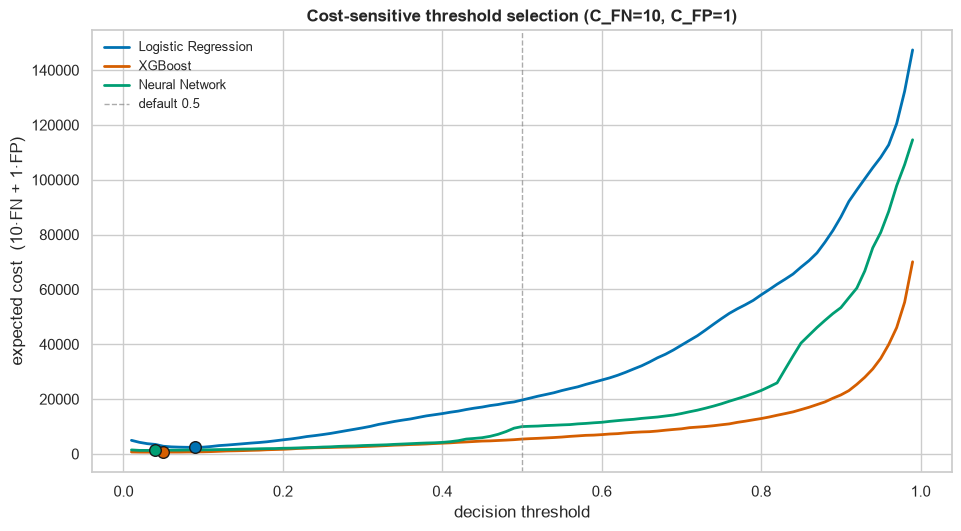

[figure saved] figures\fig13_cost_operating_points.png


In [19]:
# =====================================================================
# SECTION 10 - COST-SENSITIVE OPERATING POINTS
# =====================================================================
banner("SECTION 10 - OPERATING POINTS")
ths = np.linspace(0.01, 0.99, 99)
cost_rows = []
for name in model_names:
    proba = PROBS[name]
    for th in ths:
        pred = (proba >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test_np, pred).ravel()
        cost_rows.append({
            "Model": name, "threshold": float(th),
            "cost": COST_FN * fn + COST_FP * fp,
            "FPR": fp / max(fp + tn, 1), "TPR": tp / max(tp + fn, 1),
        })
cost_df = pd.DataFrame(cost_rows)
cost_df.to_csv(RESULTS_DIR / "threshold_cost_curves.csv", index=False)

op_rows = []
for name in model_names:
    sub = cost_df[cost_df.Model == name]
    best = sub.loc[sub.cost.idxmin()]
    ok = sub[sub.FPR <= 0.01]
    op1 = ok.loc[ok.TPR.idxmax()] if len(ok) else None
    op_rows.append({
        "Model": name,
        "min_cost": float(best.cost),
        "cost_threshold": float(best.threshold),
        "TPR_at_min_cost": float(best.TPR),
        "FPR_at_min_cost": float(best.FPR),
        "FPR<=1%_threshold": float(op1.threshold) if op1 is not None else np.nan,
        "TPR_at_FPR<=1%": float(op1.TPR) if op1 is not None else np.nan,
    })
op_df = pd.DataFrame(op_rows)
op_df.to_csv(RESULTS_DIR / "operating_points.csv", index=False)
print(op_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
for name in model_names:
    sub = cost_df[cost_df.Model == name]
    ax.plot(sub.threshold, sub.cost, color=MODEL_COLORS[name], lw=2, label=name)
    i = sub.cost.idxmin()
    ax.scatter(sub.loc[i, "threshold"], sub.loc[i, "cost"], color=MODEL_COLORS[name],
               zorder=5, edgecolor="k", s=70)
ax.axvline(0.5, color="#888888", ls="--", lw=1, alpha=0.7, label="default 0.5")
ax.set_xlabel("decision threshold")
ax.set_ylabel("expected cost  (10·FN + 1·FP)")
ax.set_title(f"Cost-sensitive threshold selection (C_FN={COST_FN:.0f}, C_FP={COST_FP:.0f})")
ax.legend(fontsize=9)
finish_fig(fig, "fig13_cost_operating_points")

## 11 · Attack-family deep-dive & a two-stage pipeline

**11A** — per-category flag rates: for every attack family, the share of its flows flagged as attack (= detection rate); for `Normal`, the share flagged (= false-alarm rate). One heatmap replaces pages of error tables.

**11B** — a practical **two-stage architecture**: Stage 1 is the binary detector; Stage 2 is a multi-class XGBoost that labels *flagged* traffic as Mirai / DoS / Scan / MITM ARP Spoofing, trained with class-balanced weights on attack flows only. This converts "something happened" into "what happened" — the difference between an alarm and a response.


  SECTION 11A - CATEGORY DETECTION RATES
                       DoS  MITM ARP Spoofing  Mirai  Normal   Scan
Logistic Regression  98.97              91.43  94.33    6.19  81.73
XGBoost              99.92              97.77  98.86    3.15  90.57
Neural Network       99.77              99.01  97.55    4.82  83.33


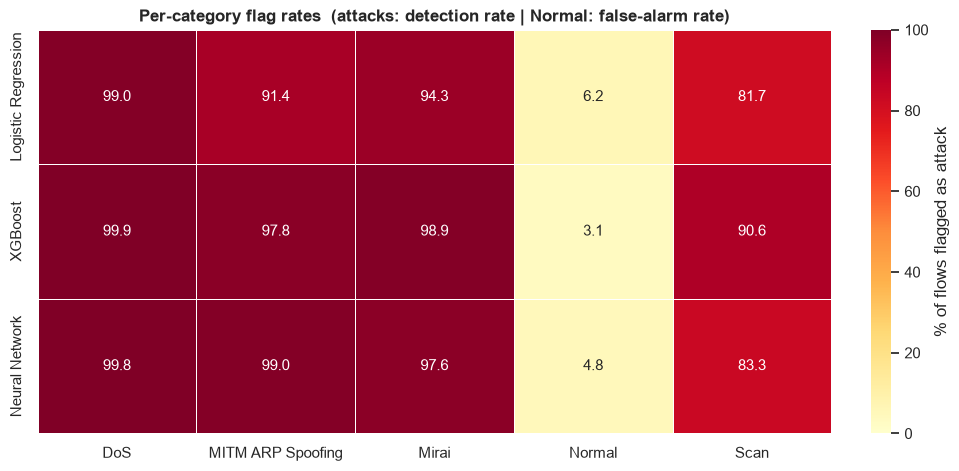

[figure saved] figures\fig14_category_detection_heatmap.png


In [20]:
# =====================================================================
# SECTION 11A - PER-CATEGORY DETECTION RATES
# =====================================================================
banner("SECTION 11A - CATEGORY DETECTION RATES")
cats = sorted(set(cat_test_np))

def category_flag_rates(pred):
    return {c: float((pred[cat_test_np == c] == 1).mean()) for c in cats}

cat_rate_df = pd.DataFrame({name: category_flag_rates(PREDS[name]) for name in model_names}).T
cat_rate_df.to_csv(RESULTS_DIR / "category_detection_rates.csv")
print((cat_rate_df * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(9.5, 4.6), constrained_layout=True)
sns.heatmap(cat_rate_df * 100, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100,
            cbar_kws={"label": "% of flows flagged as attack"}, ax=ax,
            linewidths=0.4, linecolor="white")
ax.set_title("Per-category flag rates  (attacks: detection rate | Normal: false-alarm rate)")
ax.set_ylabel(""); ax.set_xlabel("")
finish_fig(fig, "fig14_category_detection_heatmap")


  SECTION 11B - TWO-STAGE ATTACK-TYPE CLASSIFIER
attack rows -> train 81,963 | val 14,465 | test 32,144 | classes: ['DoS', 'MITM ARP Spoofing', 'Mirai', 'Scan']
                   precision  recall  f1-score    support
DoS                    0.999   0.999     0.999   5149.000
MITM ARP Spoofing      0.368   0.865     0.516   1925.000
Mirai                  0.994   0.831     0.906  22821.000
Scan                   0.515   0.775     0.619   2249.000
accuracy               0.856   0.856     0.856      0.856
macro avg              0.719   0.868     0.760  32144.000
weighted avg           0.924   0.856     0.877  32144.000


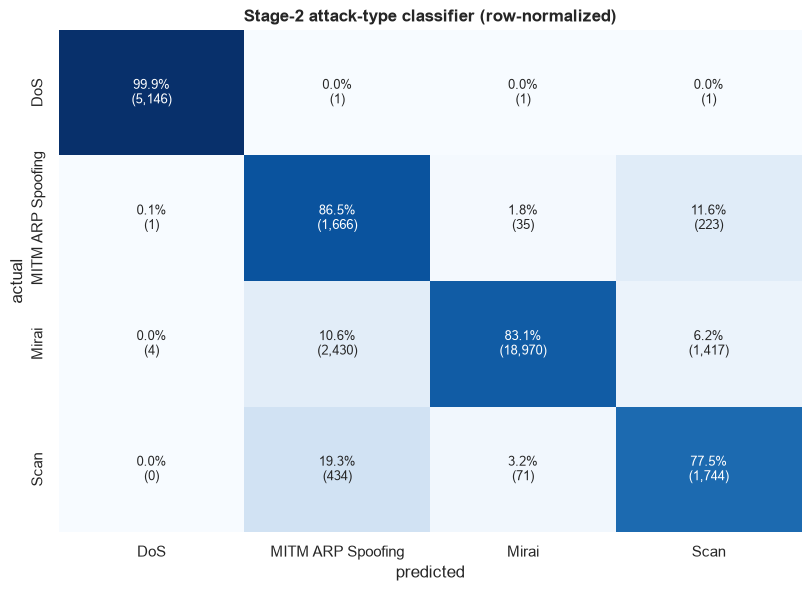

[figure saved] figures\fig15_twostage_confusion.png


['models\\xgboost_attack_type.joblib']

In [21]:
# =====================================================================
# SECTION 11B - TWO-STAGE PIPELINE: DETECT -> CLASSIFY ATTACK TYPE
# =====================================================================
banner("SECTION 11B - TWO-STAGE ATTACK-TYPE CLASSIFIER")
attack_labels = sorted([c for c in data["y_cat"].unique() if c != "Normal"])
tr_att, va_att, te_att = cat_train_np != "Normal", cat_val_np != "Normal", cat_test_np != "Normal"
X_tr_att, y_tr_att = X_train_s[tr_att], cat_train_np[tr_att]
X_va_att, y_va_att = X_val_s[va_att],  cat_val_np[va_att]
X_te_att, y_te_att = X_test_s[te_att], cat_test_np[te_att]
print(f"attack rows -> train {len(y_tr_att):,} | val {len(y_va_att):,} | test {len(y_te_att):,} | classes: {attack_labels}")

clf2 = XGBClassifier(
    n_estimators=50 if FAST_MODE else 250, learning_rate=0.1, max_depth=6,
    subsample=0.9, colsample_bytree=0.8, objective="multi:softprob",
    eval_metric="mlogloss", tree_method="hist", early_stopping_rounds=20,
    random_state=SEED, n_jobs=-1)
from sklearn.preprocessing import LabelEncoder
le2 = LabelEncoder().fit(attack_labels)
clf2.fit(X_tr_att, le2.transform(y_tr_att), eval_set=[(X_va_att, le2.transform(y_va_att))],
         sample_weight=compute_sample_weight("balanced", y_tr_att), verbose=False)
y_att_pred = le2.inverse_transform(clf2.predict(X_te_att))

report2_df = pd.DataFrame(classification_report(y_te_att, y_att_pred, output_dict=True, zero_division=0)).T
report2_df.to_csv(RESULTS_DIR / "twostage_attack_classifier_report.csv")
print(report2_df.round(3).to_string())

labels_sorted = sorted(attack_labels)
cm2 = confusion_matrix(y_te_att, y_att_pred, labels=labels_sorted)
cm2_pct = cm2 / cm2.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(8, 5.8), constrained_layout=True)
annot2 = np.array([[f"{p:.1f}%\n({v:,})" for v, p in zip(rv, rp)] for rv, rp in zip(cm2, cm2_pct)])
sns.heatmap(cm2_pct, annot=annot2, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=labels_sorted, yticklabels=labels_sorted, annot_kws={"fontsize": 9})
ax.set_title("Stage-2 attack-type classifier (row-normalized)")
ax.set_xlabel("predicted"); ax.set_ylabel("actual")
finish_fig(fig, "fig15_twostage_confusion")
joblib.dump(clf2, MODELS_DIR / "xgboost_attack_type.joblib")

## 12 · Robustness stress test

Real deployments face **noisy measurements** (counter overflows, export glitches) and **failing sensors** (a feature silently zeroed by a broken probe). We simulate both directly in feature space:
- **Gaussian noise** added in standardized units (σ from 0 to 1.0),
- **feature dropout** — a random 10/20/30% of features zeroed *per flow*.

Caveat (worth stating in a paper): this is a feature-space stress test, not a network-level adversarial attack — but it separates models that fail gracefully from models that collapse.


  SECTION 12 - ROBUSTNESS
noise sigma=0.00 done
noise sigma=0.10 done
noise sigma=0.25 done
noise sigma=0.50 done
noise sigma=0.75 done
noise sigma=1.00 done
feature dropout 0% done
feature dropout 10% done
feature dropout 20% done
feature dropout 30% done


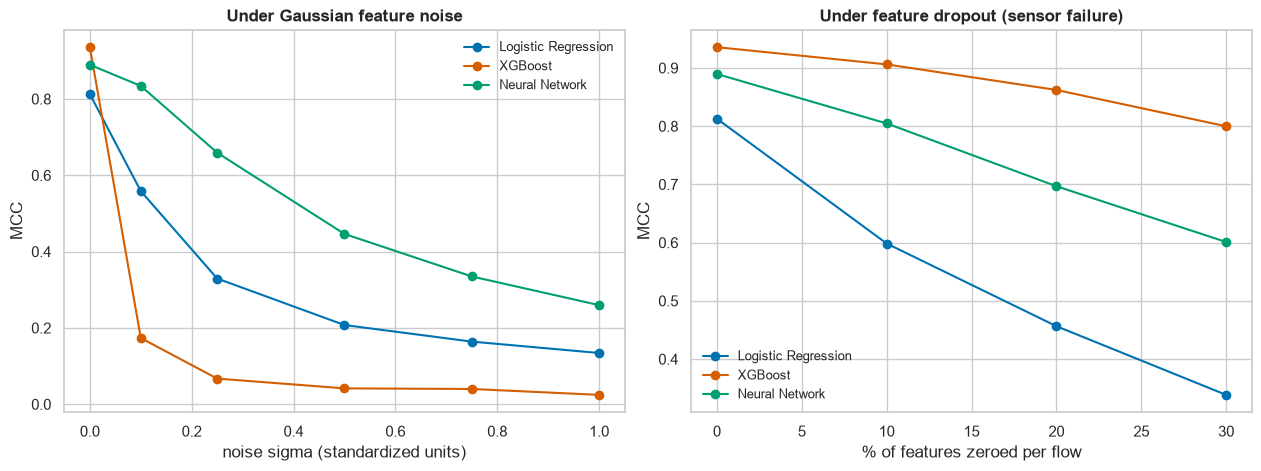

[figure saved] figures\fig16_robustness_stress.png


In [22]:
# =====================================================================
# SECTION 12 - ROBUSTNESS STRESS TEST (noise & feature dropout)
# =====================================================================
banner("SECTION 12 - ROBUSTNESS")
rng12 = np.random.default_rng(SEED)

def mcc_at(name, X_mod):
    p = np.asarray(PREDICT_FNS[name](X_mod))
    return matthews_corrcoef(y_test_np, (p >= 0.5).astype(int))

noise_rows = []
for s in NOISE_SIGMAS:
    Xn = X_test_s + rng12.normal(0.0, s, size=X_test_s.shape).astype(np.float32) if s > 0 else X_test_s
    for name in model_names:
        noise_rows.append({"sigma": s, "Model": name, "MCC": mcc_at(name, Xn)})
    print(f"noise sigma={s:.2f} done")

drop_rows = []
for pct in DROPOUT_PCTS:
    if pct > 0:
        mask = rng12.random(X_test_s.shape) < pct / 100.0
        Xd = X_test_s.copy(); Xd[mask] = 0.0        # zero in standardized space = feature removed
    else:
        Xd = X_test_s
    for name in model_names:
        drop_rows.append({"dropout_pct": pct, "Model": name, "MCC": mcc_at(name, Xd)})
    print(f"feature dropout {pct}% done")

noise_df = pd.DataFrame(noise_rows); drop_df = pd.DataFrame(drop_rows)
noise_df.to_csv(RESULTS_DIR / "robustness_noise.csv", index=False)
drop_df.to_csv(RESULTS_DIR / "robustness_dropout.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
for name in model_names:
    sub = noise_df[noise_df.Model == name]
    axes[0].plot(sub.sigma, sub.MCC, "o-", color=MODEL_COLORS[name], label=name)
    sub2 = drop_df[drop_df.Model == name]
    axes[1].plot(sub2.dropout_pct, sub2.MCC, "o-", color=MODEL_COLORS[name], label=name)
axes[0].set_xlabel("noise sigma (standardized units)"); axes[0].set_ylabel("MCC")
axes[0].set_title("Under Gaussian feature noise")
axes[1].set_xlabel("% of features zeroed per flow"); axes[1].set_ylabel("MCC")
axes[1].set_title("Under feature dropout (sensor failure)")
axes[0].legend(fontsize=9); axes[1].legend(fontsize=9)
finish_fig(fig, "fig16_robustness_stress")

## 13 · Temporal generalization check

Random splits are the quiet default of most IDS papers — but real detectors are trained on *the past* and defend *the future*. We rebuild the XGBoost protocol with a **time-ordered split** (first 70% of flows → train, next 15% → validation, last 15% → test) and compare per-category behaviour against the random split.

A gap between the two columns is the *optimism budget* of random-split evaluation — a methodological point reviewers like to see quantified.


  SECTION 13 - TEMPORAL SPLIT
temporal MCC=0.0000 vs random-split MCC=0.9356 | gap=+0.9356
          random_flag_rate  temporal_flag_rate
category                                      
Mirai                98.86               91.47


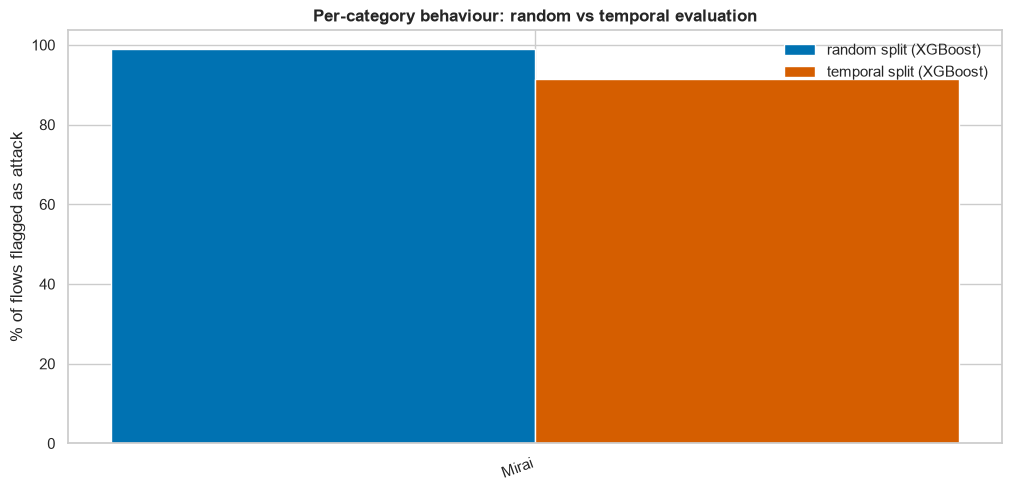

[figure saved] figures\fig17_temporal_generalization.png


In [23]:
# =====================================================================
# SECTION 13 - TEMPORAL GENERALIZATION CHECK
# =====================================================================
banner("SECTION 13 - TEMPORAL SPLIT")
temporal_gap = None
_ts_arr = data["_ts"].to_numpy()
if pd.notna(_ts_arr).mean() <= 0.9:
    print("Timestamps unavailable/unparseable -> temporal check skipped (random-split results remain valid).")
else:
    valid = np.where(pd.notna(_ts_arr))[0]
    order = valid[np.argsort(_ts_arr[valid])]
    n13 = len(order)
    i_tr, i_va = int(n13 * 0.70), int(n13 * 0.85)
    sl = {"train": order[:i_tr], "val": order[i_tr:i_va], "test": order[i_va:]}

    Xt_df = X_all.iloc[sl["train"]][FEATURE_COLS_KEEP].copy(); Xt_df.fillna(train_medians, inplace=True)
    Xv_df = X_all.iloc[sl["val"]][FEATURE_COLS_KEEP].copy();   Xv_df.fillna(train_medians, inplace=True)
    Xs_df = X_all.iloc[sl["test"]][FEATURE_COLS_KEEP].copy();  Xs_df.fillna(train_medians, inplace=True)
    st13 = StandardScaler().fit(Xt_df)
    Xt_s, Xv_s13, Xs_s13 = st13.transform(Xt_df).astype(np.float32), st13.transform(Xv_df).astype(np.float32), st13.transform(Xs_df).astype(np.float32)

    yt, yv, ys = data["y_bin"].to_numpy()[sl["train"]], data["y_bin"].to_numpy()[sl["val"]], data["y_bin"].to_numpy()[sl["test"]]
    ct13 = data["y_cat"].to_numpy()[sl["test"]]
    neg13, pos13 = np.bincount(yt, minlength=2)
    neg13, pos13 = max(neg13, 1), max(pos13, 1)

    xgb_time = XGBClassifier(
        n_estimators=60 if FAST_MODE else 300, learning_rate=0.1, max_depth=6,
        subsample=0.9, colsample_bytree=0.8, objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", scale_pos_weight=neg13 / pos13, early_stopping_rounds=25,
        random_state=SEED, n_jobs=-1)
    xgb_time.fit(Xt_s, yt, eval_set=[(Xv_s13, yv)], verbose=False)
    pred_t = (xgb_time.predict_proba(Xs_s13)[:, 1] >= 0.5).astype(int)

    tm = {"Model": "XGBoost (temporal split)",
          "Accuracy": accuracy_score(ys, pred_t),
          "BalancedAcc": balanced_accuracy_score(ys, pred_t),
          "MCC": matthews_corrcoef(ys, pred_t),
          "F1_macro": f1_score(ys, pred_t, average="macro", zero_division=0)}
    rand_mcc = float(metrics_df.loc[metrics_df.Model == "XGBoost", "MCC"].iloc[0])
    temporal_gap = rand_mcc - tm["MCC"]
    pd.DataFrame([tm]).to_csv(RESULTS_DIR / "temporal_metrics.csv", index=False)
    print(f"temporal MCC={tm['MCC']:.4f} vs random-split MCC={rand_mcc:.4f} | gap={temporal_gap:+.4f}")

    rows13 = []
    for c in cats:
        m_time = ct13 == c
        if m_time.sum() == 0:
            continue
        m_rand = cat_test_np == c
        rows13.append({"category": c,
                       "random_flag_rate": float((PREDS["XGBoost"][m_rand] == 1).mean()),
                       "temporal_flag_rate": float((pred_t[m_time] == 1).mean())})
    comp13 = pd.DataFrame(rows13)
    comp13.to_csv(RESULTS_DIR / "temporal_vs_random.csv", index=False)
    print((comp13.set_index("category") * 100).round(2).to_string())

    fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
    xpos = np.arange(len(comp13)); w13 = 0.38
    ax.bar(xpos - w13/2, comp13.random_flag_rate * 100, w13, label="random split (XGBoost)", color="#0072B2")
    ax.bar(xpos + w13/2, comp13.temporal_flag_rate * 100, w13, label="temporal split (XGBoost)", color="#D55E00")
    ax.set_xticks(xpos); ax.set_xticklabels(comp13.category, rotation=20, ha="right")
    ax.set_ylabel("% of flows flagged as attack")
    ax.set_title("Per-category behaviour: random vs temporal evaluation")
    ax.legend()
    finish_fig(fig, "fig17_temporal_generalization")

## 14 · Ensembles & hard-sample forensics

Two cheap ensembles — **majority vote** and **soft vote** (mean probability) — tell us whether the three models make *different* mistakes. The difficulty histogram then stratifies every test flow by *how many models got it wrong*; the stacked composition shows which traffic categories make up the "hard core" that **all models miss** — the honest frontier of what these flow features can express.


  SECTION 14 - ENSEMBLE & HARD SAMPLES
[Soft Vote (mean prob)] acc=0.9787 | balAcc=0.9682 | MCC=0.9264 | F1(macro)=0.9632 | ROC-AUC=0.9953 | PR-AUC=0.9989
majority-vote agreement with best single model: 98.04%


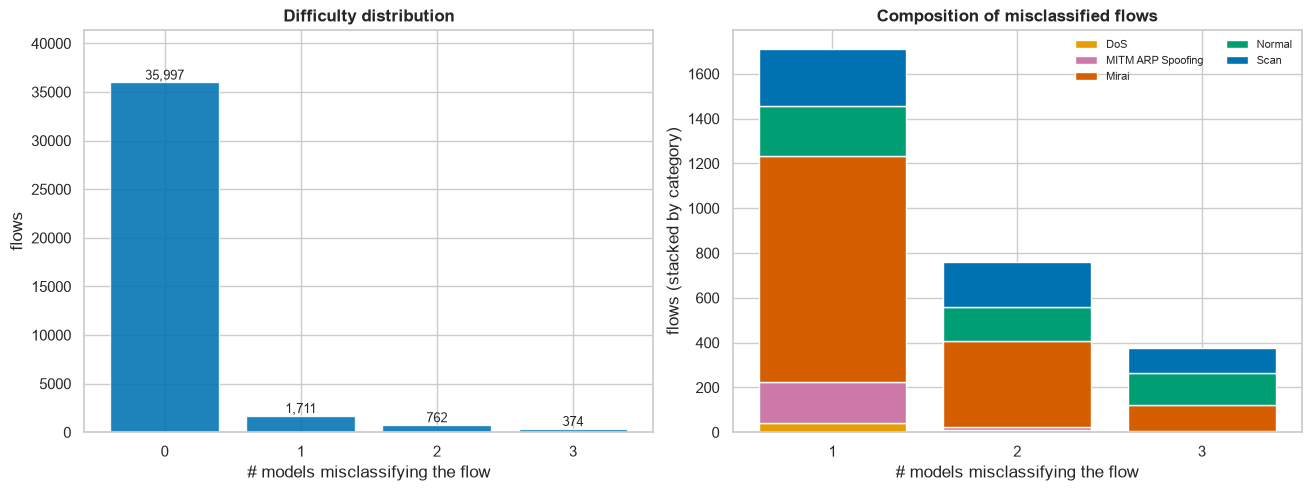

[figure saved] figures\fig18_ensemble_hard_samples.png

categories most often missed by ALL models:
Normal               142
Mirai                114
Scan                 111
DoS                    4
MITM ARP Spoofing      3


In [24]:
# =====================================================================
# SECTION 14 - ENSEMBLES & HARD-SAMPLE FORENSICS
# =====================================================================
banner("SECTION 14 - ENSEMBLE & HARD SAMPLES")

def _metrics_hard(name, pred):
    RESULTS_ROWS.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_np, pred),
        "BalancedAcc": balanced_accuracy_score(y_test_np, pred),
        "Precision_anomaly": precision_score(y_test_np, pred, pos_label=1, zero_division=0),
        "Recall_anomaly": recall_score(y_test_np, pred, pos_label=1, zero_division=0),
        "F1_anomaly": f1_score(y_test_np, pred, pos_label=1, zero_division=0),
        "F1_macro": f1_score(y_test_np, pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_test_np, pred),
        "ROC_AUC": np.nan, "PR_AUC": np.nan, "Brier": np.nan, "train_sec": np.nan,
    })
    PREDS[name] = pred

pred_mat = np.vstack([PREDS[n] for n in model_names])
_metrics_hard("Majority Vote (3 models)", (pred_mat.mean(axis=0) >= 0.5).astype(int))
soft = (PROBS["Logistic Regression"] + PROBS["XGBoost"] + PROBS["Neural Network"]) / 3.0
evaluate_binary("Soft Vote (mean prob)", y_test_np, soft)
print(f"majority-vote agreement with best single model: "
      f"{(PREDS['Majority Vote (3 models)'] == PREDS[max(model_names, key=lambda m: metrics_df.loc[metrics_df.Model == m, 'MCC'].iloc[0])]).mean()*100:.2f}%")

# ---- difficulty & composition ----
err_stack = np.vstack([(PREDS[n] != y_test_np) for n in model_names]).sum(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
counts14 = pd.Series(err_stack).value_counts().sort_index()
axes[0].bar(counts14.index.astype(str), counts14.values, color="#0072B2", alpha=0.88)
for xv, v in zip(counts14.index.astype(str), counts14.values):
    axes[0].annotate(f"{v:,}", (xv, v), ha="center", va="bottom", fontsize=9)
axes[0].set_xlabel("# models misclassifying the flow"); axes[0].set_ylabel("flows")
axes[0].set_title("Difficulty distribution")
axes[0].set_ylim(0, counts14.max() * 1.15)

comp14 = (pd.DataFrame({"cat": cat_test_np, "err": err_stack})
            .query("err > 0").groupby(["err", "cat"]).size().unstack(fill_value=0))
bottom14 = np.zeros(len(comp14))
for c in comp14.columns:
    axes[1].bar(comp14.index.astype(str), comp14[c].values, bottom=bottom14,
                color=CAT_COLORS.get(c, "#9E9E9E"), label=c)
    bottom14 += comp14[c].values
axes[1].set_xlabel("# models misclassifying the flow")
axes[1].set_ylabel("flows (stacked by category)")
axes[1].set_title("Composition of misclassified flows")
axes[1].legend(fontsize=8, ncol=2)
finish_fig(fig, "fig18_ensemble_hard_samples")

hard_cat = pd.Series(cat_test_np[err_stack == len(model_names)]).value_counts()
print("\ncategories most often missed by ALL models:")
print(hard_cat.to_string())

## 15 · Final summary, radar & exports

The radar chart normalizes six criteria across the three models (min–max): three quality axes (Balanced Accuracy, MCC, F1-macro, ROC-AUC) plus **Speed** (`1/log10(latency)`) and **Compactness** (`1/log10(size)`). Everything is exported to `results/` for the paper and GitHub.


  SECTION 15 - FINAL SUMMARY
                   Model  Accuracy  BalancedAcc  Precision_anomaly  Recall_anomaly  F1_anomaly  F1_macro    MCC  ROC_AUC  PR_AUC  Brier  latency_us_b1  throughput_kpps  model_size_KB  train_sec
     Logistic Regression    0.9398       0.9391             0.9865          0.9401      0.9627    0.9029 0.8127   0.9830  0.9959 0.0461       108.5837       10604.4530         1.1045     1.9746
                 XGBoost    0.9812       0.9762             0.9934          0.9838      0.9886    0.9676 0.9356   0.9974  0.9994 0.0139       375.9797        1225.9259       825.2637     4.2154
          Neural Network    0.9669       0.9609             0.9897          0.9700      0.9798    0.9441 0.8896   0.9937  0.9986 0.0225       103.1963        4160.5991        69.7822    19.1535
Majority Vote (3 models)    0.9708       0.9650             0.9907          0.9738      0.9822    0.9504 0.9018      NaN     NaN    NaN            NaN              NaN            NaN        NaN


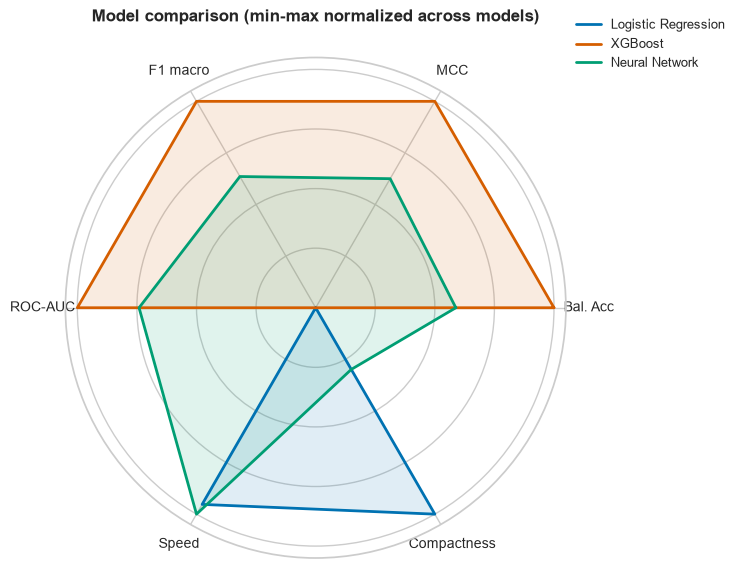

[figure saved] figures\fig19_radar_summary.png

KEY FINDINGS
 - Best detection quality: XGBoost (MCC=0.9356, balanced accuracy=0.9762).
 - Fastest detector: Neural Network at 103.2 us/flow (4,161k flows/s, 70 KB).
 - Feature budget: 10 of 67 features keep MCC within 0.01 of the full set (0.9375).
 - Cost-aware thresholding (C_FN=10, C_FP=1) on XGBoost reduces expected alert cost by 88% vs the default 0.5 rule.
 - MCC drop under maximal noise (sigma=1.00): Logistic Regression 0.678, Neural Network 0.630, XGBoost 0.911.
 - Temporal split costs XGBoost +0.9356 MCC vs the random split - random-split numbers are optimistic.
 - Hardest flows (missed by all models) are dominated by: Normal (142), Mirai (114), Scan (111).

ARTIFACTS WRITTEN
  figures\fig01_class_distribution.png
  figures\fig02_feature_correlation.png
  figures\fig03_dummy_baselines.png
  figures\fig04_mlp_training_curve.png
  figures\fig05_confusion_matrices.png
  figures\fig06_roc_pr_curves.png
  figures\fig07_calibration_cu

In [25]:
# =====================================================================
# SECTION 15 - FINAL SUMMARY, RADAR & ARTIFACT EXPORT
# =====================================================================
banner("SECTION 15 - FINAL SUMMARY")
final_df = pd.DataFrame(RESULTS_ROWS).merge(
    eff_df[["Model", "latency_us_b1", "throughput_kpps", "model_size_KB"]],
    on="Model", how="left")
final_df = final_df[["Model", "Accuracy", "BalancedAcc", "Precision_anomaly", "Recall_anomaly",
                     "F1_anomaly", "F1_macro", "MCC", "ROC_AUC", "PR_AUC", "Brier",
                     "latency_us_b1", "throughput_kpps", "model_size_KB", "train_sec"]]
final_df.to_csv(RESULTS_DIR / "results_summary.csv", index=False)
print(final_df.round(4).to_string(index=False))

# ---- radar over the 3 core models ----
radar_metrics = ["BalancedAcc", "MCC", "F1_macro", "ROC_AUC", "latency_us_b1", "model_size_KB"]
core = final_df[final_df.Model.isin(model_names)].set_index("Model")
norm = core[radar_metrics].copy()
norm["latency_us_b1"] = 1.0 / np.log10(norm["latency_us_b1"] + 10.0)   # speed score
norm["model_size_KB"] = 1.0 / np.log10(norm["model_size_KB"] + 10.0)   # compactness score
mins, maxs = norm.min(), norm.max()
norm_n = (norm - mins) / (maxs - mins + 1e-12)

labels_r = ["Bal. Acc", "MCC", "F1 macro", "ROC-AUC", "Speed", "Compactness"]
ang = np.linspace(0, 2 * np.pi, len(labels_r), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(7.5, 6.5))
ax = fig.add_subplot(111, polar=True)
for name in model_names:
    vals = norm_n.loc[name].tolist(); vals += vals[:1]
    ax.plot(ang, vals, color=MODEL_COLORS[name], lw=2, label=name)
    ax.fill(ang, vals, color=MODEL_COLORS[name], alpha=0.12)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels_r, fontsize=10)
ax.set_yticks([0.25, 0.5, 0.75, 1.0]); ax.set_yticklabels([])
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison (min-max normalized across models)", pad=26)
ax.legend(loc="upper right", bbox_to_anchor=(1.34, 1.10), fontsize=9)
finish_fig(fig, "fig19_radar_summary")

# ---- automatically generated key findings ----
lines = []
best_row = final_df.loc[final_df.MCC.idxmax()]
lines.append(f"Best detection quality: {best_row.Model} "
             f"(MCC={best_row.MCC:.4f}, balanced accuracy={best_row.BalancedAcc:.4f}).")
fast_row = final_df.loc[final_df.latency_us_b1.idxmin()]
lines.append(f"Fastest detector: {fast_row.Model} at {fast_row.latency_us_b1:.1f} us/flow "
             f"({fast_row.throughput_kpps:,.0f}k flows/s, {fast_row.model_size_KB:,.0f} KB).")
lines.append(f"Feature budget: {knee_k} of {n_feat_total} features keep MCC within 0.01 of the full set "
             f"({full_mcc:.4f}).")
cost_05 = cost_df[np.isclose(cost_df.threshold, 0.5)].set_index("Model").cost
min_cost_s = op_df.set_index("Model").min_cost
best_cost_model = min_cost_s.idxmin()
if cost_05[best_cost_model] > 0:
    savings = 1.0 - min_cost_s.min() / cost_05[best_cost_model]
    lines.append(f"Cost-aware thresholding (C_FN={COST_FN:.0f}, C_FP={COST_FP:.0f}) on {best_cost_model} "
                 f"reduces expected alert cost by {100*savings:.0f}% vs the default 0.5 rule.")
piv16 = noise_df.pivot(index="sigma", columns="Model", values="MCC")
drops16 = piv16.iloc[0] - piv16.iloc[-1]
lines.append("MCC drop under maximal noise (sigma={:.2f}): ".format(piv16.index[-1]) +
             ", ".join(f"{m} {v:.3f}" for m, v in drops16.items()) + ".")
if temporal_gap is not None:
    lines.append(f"Temporal split costs XGBoost {temporal_gap:+.4f} MCC vs the random split - "
                 "random-split numbers are optimistic.")
hard_top = pd.Series(cat_test_np[err_stack == len(model_names)]).value_counts()
if len(hard_top):
    lines.append("Hardest flows (missed by all models) are dominated by: " +
                 ", ".join(f"{k} ({v:,})" for k, v in hard_top.head(3).items()) + ".")
(RESULTS_DIR / "key_findings.txt").write_text("\n".join(f"- {l}" for l in lines), encoding="utf-8")
print("\nKEY FINDINGS")
for l in lines:
    print(" -", l)

print("\nARTIFACTS WRITTEN")
for d in (FIG_DIR, RESULTS_DIR, MODELS_DIR):
    for p in sorted(d.iterdir()):
        if p.is_file():
            print(f"  {p}")

## Reading guide & paper mapping

| Notebook artifact | Suggested paper role |
|---|---|
| `fig03_dummy_baselines` | Motivation: the accuracy pitfall of attack-majority IDS data |
| `fig05–fig07` | Evaluation: confusion, ROC, dual-view PR, calibration |
| `fig08_efficiency_pareto` | Deployment feasibility (latency/size/quality in one figure) |
| `fig09–fig11` | Interpretability section (SHAP + per-family profiles) |
| `fig12_feature_reduction` | Contribution: lightweight feature budget |
| `fig13_cost_operating_points` | Contribution: cost-aware operating points |
| `fig14–fig15` | Category-level analysis + two-stage detection/classification |
| `fig16_robustness_stress` | Robustness analysis |
| `fig17_temporal_generalization` | Methodological critique of random splits |
| `fig18_ensemble_hard_samples` | Error forensics / future-work paragraph |
| `results/key_findings.txt`, `results_summary.csv` | Abstract + Table 1 numbers |

**Suggested next steps**
1. Re-run top-to-bottom on your machine (FAST_MODE first if you want a quick look), then keep the full run.
2. Push the repo with: notebook + `requirements.txt` + `README.md` + `figures/` + `results/`.
3. Draft the paper skeleton around the figure mapping above — every table in `results/` is already paper-shaped.